## Creation of mouse objects

In [1]:
class DFStore(dict):
    """A dict that only accepts pandas-like DataFrames as values."""
    @staticmethod
    def _looks_like_pandas_df(obj):
        # Heuristic: works for pandas DataFrame without importing pandas
        return hasattr(obj, "columns") and hasattr(obj, "dtypes") and hasattr(obj, "shape")

    def __setitem__(self, key, value):
        if not self._looks_like_pandas_df(value):
            raise TypeError("dfs can only contain pandas DataFrames.")
        super().__setitem__(str(key), value)

    def update(self, mapping=(), **kwargs):
        items = dict(mapping, **kwargs).items()
        for k, v in items:
            self[k] = v  # routes through __setitem__ for validation


class Trial:
    """
    Simple container for a single trial.

    Attributes:
        base_dir (str): Base directory for the trial.
        trial_id (str): Identifier of the trial.
        mouse_id (str): Identifier of the mouse.
        dfs (DFStore): Dict-like store that accepts DataFrames only.
        tracking (str): Path to a .csv tracking file.
        video (str): Path to a .mp4 video file.
    """

    def __init__(self, base_dir, trial_id, mouse_id, tracking=None, video=None):
        self.base_dir = str(base_dir)
        self.trial_id = str(trial_id)
        self.mouse_id = str(mouse_id)

        # --- Add more attributes here if needed (e.g., "session_date", "genotype") ---

        self.dfs = DFStore()
        self.tracking = None
        self.video = None

        if tracking is not None:
            self.set_tracking(tracking)
        if video is not None:
            self.set_video(video)

    def set_tracking(self, path):
        path = str(path)
        if not path.lower().endswith(".csv"):
            raise ValueError("tracking must be a path to a .csv file.")
        self.tracking = path
        return self

    def set_video(self, path):
        path = str(path)
        if not path.lower().endswith(".mp4"):
            raise ValueError("video must be a path to a .mp4 file.")
        self.video = path
        return self

    # Convenience helpers
    def put_df(self, name, df):
        """Insert a single DataFrame into dfs."""
        self.dfs[name] = df
        return self

    def put_dfs(self, mapping):
        """Insert many DataFrames at once: {'name': df, ...}."""
        self.dfs.update(mapping)
        return self

    def __getitem__(self, name):
        return self.dfs[name]

    def __repr__(self):
        keys = ", ".join(sorted(self.dfs.keys()))
        return (
            f"Trial(base_dir={self.base_dir!r}, trial_id={self.trial_id!r}, "
            f"mouse_id={self.mouse_id!r}, dfs=[{keys}], "
            f"tracking_set={self.tracking is not None}, video_set={self.video is not None})"
        )


In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
from pathlib import Path
import pandas as pd

In [4]:
base_path = "/home/fsp585/Desktop/FiberphotometryCode/src_oft/soeren"

csv_path = Path(base_path + "/csvs")
h5_path = Path(base_path + "/h5_files")
video_path = Path(base_path + "/video_files")

In [5]:
def _first(path_iterable):
    """Return the first Path from an iterable (sorted), or None."""
    items = sorted(path_iterable)
    return items[0] if items else None

import re

def _infer_mouse_id_from_csv(sig_df, trk_df):
    def _single_val(series):
        vals = series.dropna().unique().tolist()
        return vals[0] if vals else None

    # Try signal first, then tracking
    for df in (sig_df, trk_df):
        if df is not None and "MouseNumber" in df.columns:
            v = _single_val(df["MouseNumber"])
            if v is not None:
                return str(v)
    return None

def _sanitize_suffix_to_digits(suffix):
    # pull a long-ish sequence of digits (e.g., 1092 from "1092" or from "70.3831186005214" → None)
    m = re.search(r"\d{3,}", suffix)  # require at least 3 digits to avoid grabbing "10" from "T10"
    return m.group(0) if m else None

def build_trials(csv_root, h5_root, video_root, base_dir):
    trials = []
    for sub in sorted(csv_root.iterdir()):
        if not sub.is_dir():
            continue

        name = sub.name  # e.g., "T1_1193" or "T13_70.3831186005214"
        if "_" not in name:
            continue

        trial_id, suffix = name.split("_", 1)

        # find per-trial CSVs
        signal_csv = _first(sub.glob("sig_data_with_zDFF_Salient_mus*.csv"))
        tracking_df_csv = _first(sub.glob("TrackingData_Salient_mus*.csv"))
        if signal_csv is None or tracking_df_csv is None:
            continue

        sig_df = pd.read_csv(signal_csv)
        trk_df = pd.read_csv(tracking_df_csv)

        # choose the best mouse id
        mouse_id = _infer_mouse_id_from_csv(sig_df, trk_df)
        if mouse_id is None:
            # fallback to folder suffix, but sanitize to digits if possible
            mouse_id = _sanitize_suffix_to_digits(suffix) or suffix  # final fallback: raw suffix as string

        # external tracking path + video path
        tracking_path = _first(h5_root.glob(f"{trial_id}_Tracking_video*.csv"))
        video_file = _first(video_root.glob(f"{trial_id}_Tracking_video*.mp4"))

        t = Trial(base_dir=base_dir, trial_id=trial_id, mouse_id=str(mouse_id))
        if tracking_path is not None:
            t.set_tracking(str(tracking_path))
        if video_file is not None:
            t.set_video(str(video_file))

        t.put_dfs({"signal": sig_df, "tracking": trk_df})

        # (optional) also store the verified mouse number from CSVs
        try:
            # if both dfs had the same MouseNumber, you can record it
            if "MouseNumber" in sig_df.columns and "MouseNumber" in trk_df.columns:
                s = sig_df["MouseNumber"].dropna().unique()
                r = trk_df["MouseNumber"].dropna().unique()
                if len(s) == 1 and len(r) == 1 and s[0] == r[0]:
                    t.mouse_number = str(s[0])
        except Exception:
            pass

        trials.append(t)

    return trials

In [6]:
# usage
trials = build_trials(csv_path, h5_path, video_path, base_path)
len(trials), trials[0]

(19,
 Trial(base_dir='/home/fsp585/Desktop/FiberphotometryCode/src_oft/soeren', trial_id='T10', mouse_id='1092', dfs=[signal, tracking], tracking_set=True, video_set=True))

In [7]:
def rename_signal_fibers(trials, fiber_map_by_trial=None, default_map=None, strict=False):
    """
    In-place rename of columns in t.dfs['signal']:
    - Replaces any 'Fiber{N}' token in a column name with its region (e.g., 'VS', 'DS').
    - Keeps the rest of the column name unchanged (e.g., 'Fiber1_Scaled_dFF' -> 'VS_Scaled_dFF').

    Args:
        trials: list[Trial]
        fiber_map_by_trial: dict like {'T1': {'Fiber1':'VS','Fiber3':'DS'}, ...}
        default_map: dict like {'Fiber1':'VS','Fiber3':'DS'} used as fallback
        strict: if True, raise KeyError when a column contains 'FiberN' without a mapping

    Returns:
        list of (trial_id, n_columns_changed)
    """
    import re

    fiber_map_by_trial = fiber_map_by_trial or {}
    default_map = default_map or {}
    pat = re.compile(r'(?<!\w)Fiber(?P<num>\d+)(?!\d)', re.IGNORECASE)

    summary = []
    for t in trials:
        sig = t.dfs.get("signal")
        if sig is None:
            continue

        trial_map = fiber_map_by_trial.get(t.trial_id, {})

        def swap(col):
            def repl(m):
                key = f"Fiber{m.group('num')}"
                region = trial_map.get(key) or default_map.get(key)
                if region is None:
                    if strict:
                        raise KeyError(f"No mapping for {t.trial_id}: {key}")
                    return m.group(0)  # leave 'FiberN' unchanged
                return str(region)

            return pat.sub(repl, col)

        old_cols = list(sig.columns)
        new_cols = [swap(c) for c in old_cols]
        sig.columns = new_cols
        summary.append((t.trial_id, sum(o != n for o, n in zip(old_cols, new_cols))))

    return summary


In [8]:
default_map = {"Fiber1": "VS", "Fiber3": "DS"}  # typical case

# apply in-place
changes = rename_signal_fibers(trials, None, default_map, strict=False)
print(changes[:5])


[('T10', 10), ('T11', 10), ('T12', 10), ('T13', 10), ('T14', 10)]


## Synchronization

In [9]:
def _get_tracking_df(trial):
    """Return tracking DF under key 'tracking' (accept old 'tracking_df' alias)."""
    trk = trial.dfs.get("tracking")
    if trk is None and "tracking_df" in trial.dfs:
        trk = trial.dfs["tracking_df"]
        trial.dfs["tracking"] = trk
        del trial.dfs["tracking_df"]
    return trk


def prepare_trial_metadata_and_times(trial):
    """
    - Ensure tracking DF is stored under 'tracking'
    - Verify Genotype / MouseNumber match between signal & tracking; save as attributes
    - Drop Genotype / MouseNumber columns from both DFs
    - Rename SecFromZero -> SecFromZero_signal (signal) and SecFromZero_tracking (tracking)
    - Compute SecFromZero_sync on tracking (aligned to photometry zero via Bonsai* timestamps)
    """
    sig = trial.dfs.get("signal")
    trk = _get_tracking_df(trial)
    if sig is None or trk is None:
        raise ValueError(f"{trial.trial_id}: missing 'signal' or 'tracking' DataFrame")

    # --- Genotype / MouseNumber consistency ---
    def _single_value(series, name):
        vals = series.dropna().unique().tolist()
        if len(vals) == 0:
            return None
        if len(vals) > 1:
            raise ValueError(f"{trial.trial_id}: {name} has multiple values in one DF: {vals[:5]}")
        return vals[0]

    if "Genotype" in sig.columns and "Genotype" in trk.columns:
        g_sig = _single_value(sig["Genotype"], "Genotype (signal)")
        g_trk = _single_value(trk["Genotype"], "Genotype (tracking)")
        if g_sig != g_trk:
            raise ValueError(f"{trial.trial_id}: Genotype mismatch signal={g_sig} tracking={g_trk}")
        trial.genotype = g_sig

    if "MouseNumber" in sig.columns and "MouseNumber" in trk.columns:
        m_sig = _single_value(sig["MouseNumber"], "MouseNumber (signal)")
        m_trk = _single_value(trk["MouseNumber"], "MouseNumber (tracking)")
        if m_sig != m_trk:
            raise ValueError(f"{trial.trial_id}: MouseNumber mismatch signal={m_sig} tracking={m_trk}")
        trial.mouse_number = m_sig  # separate from trial.mouse_id if you want both

    # Drop from both
    for df in (sig, trk):
        for col in ("Genotype", "MouseNumber"):
            if col in df.columns:
                df.drop(columns=[col], inplace=True)

    # --- Rename SecFromZero columns
    if "SecFromZero" in sig.columns and "SecFromZero_signal" not in sig.columns:
        sig.rename(columns={"SecFromZero": "SecFromZero_signal"}, inplace=True)
    if "SecFromZero" in trk.columns and "SecFromZero_tracking" not in trk.columns:
        trk.rename(columns={"SecFromZero": "SecFromZero_tracking"}, inplace=True)

    # --- Compute tracking SecFromZero_sync using Bonsai timestamps and signal t0
    # (don't rely on SecFromZero_tracking per your instructions)
    if "BonsaiFlyTimestamp" not in sig.columns or "BonsaiTrackingTimestamp" not in trk.columns:
        raise ValueError(f"{trial.trial_id}: missing Bonsai* timestamp columns for sync")
    if "SecFromZero_sync" not in trk.columns:
        t0 = sig["BonsaiFlyTimestamp"].iloc[0]
        trk["SecFromZero_sync"] = trk["BonsaiTrackingTimestamp"] - t0

    # Write back (not strictly necessary since we edited in place)
    trial.dfs["signal"] = sig
    trial.dfs["tracking"] = trk
    return trial


def prepare_all_trials(trials):
    """Run the preparation on each trial."""
    for t in trials:
        prepare_trial_metadata_and_times(t)
    return trials

In [10]:
def align_trial_sparse(
    trial,
    tracking_fps=60,                        # 60 Hz master grid
    signal_fps=20,                          # 20 Hz photometry (for tolerance only)
    tracking_time_col="SecFromZero_sync",   # tracking time aligned to photometry zero
    signal_time_col="SecFromZero_signal"    # signal time (same zero)
):
    """
    Build a 60 Hz master grid:
      - tracking: value at every grid tick (nearest within half a frame)
      - signal  : value ONLY at grid ticks that correspond to a true signal sample (sparse)
    No prefixes; raises on name collisions.
    """
    sig = trial.dfs.get("signal")
    trk = trial.dfs.get("tracking")
    if trk is None and "tracking_df" in trial.dfs:
        trk = trial.dfs["tracking_df"]
        trial.dfs["tracking"] = trk
        del trial.dfs["tracking_df"]
    if sig is None or trk is None:
        raise ValueError(f"{trial.trial_id}: missing 'signal' or 'tracking' DataFrame")

    # Ensure tracking has synced time (photometry zero)
    if tracking_time_col not in trk.columns:
        t0 = sig["BonsaiFlyTimestamp"].iloc[0]
        trk[tracking_time_col] = trk["BonsaiTrackingTimestamp"] - t0

    # 1) Build 60 Hz grid from 0 to overlap end
    t_end = float(min(sig[signal_time_col].max(), trk[tracking_time_col].max()))
    step = 1.0 / float(tracking_fps)
    n = int(t_end / step) + 1
    grid = pd.Index([i * step for i in range(n)], name="time")
    grid_df = pd.DataFrame({"time": grid.values})  # sorted

    # 2) Tracking → grid (dense; nearest within half a tracking frame)
    trk_sorted = (
        trk.reset_index(drop=False)
           .rename(columns={"index": "tracking_index"})
           .sort_values(tracking_time_col)
    )
    tol_trk = 0.5 / float(tracking_fps)
    trk_on_grid = pd.merge_asof(
        left=grid_df,
        right=trk_sorted,
        left_on="time",
        right_on=tracking_time_col,
        direction="nearest",
        tolerance=tol_trk
    ).set_index("time")

    # 3) Signal → grid (sparse; snap each true sample to ONE grid tick)
    sig_sorted = (
        sig.reset_index(drop=False)
           .rename(columns={"index": "signal_index"})
           .sort_values(signal_time_col)
    )
    sig_to_grid = pd.merge_asof(
        left=sig_sorted,
        right=grid_df,
        left_on=signal_time_col,
        right_on="time",
        direction="nearest",
        tolerance=tol_trk   # half of 1/60 s
    )
    sig_to_grid = sig_to_grid.dropna(subset=["time"]).set_index("time")
    sig_on_grid = sig_to_grid[~sig_to_grid.index.duplicated(keep="first")]

    # 4) Collision check (no prefixes)
    collisions = sorted(set(trk_on_grid.columns) & set(sig_on_grid.columns))
    if collisions:
        raise ValueError(
            "Column name collision between tracking and signal: "
            + ", ".join(collisions)
            + ". Rename/drop before aligning."
        )

    # 5) Join: tracking dense; signal sparse
    return trk_on_grid.join(sig_on_grid, how="left")

In [11]:
# Prep once (drops cols, stores attributes, renames SecFromZero, computes sync)
prepare_all_trials(trials)

# Align a trial on the 60 Hz master clock without prefixes or collisions
aligned = align_trial_sparse(trials[0])

aligned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 350473 entries, 0.0 to 5841.2
Data columns (total 22 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   tracking_index           333350 non-null  float64
 1   BonsaiTrackingTimestamp  333350 non-null  float64
 2   Dist1                    333350 non-null  float64
 3   SecFromZero_tracking     333350 non-null  float64
 4   DistClean                333350 non-null  float64
 5   DistClean_CM             333350 non-null  float64
 6   SecFromZero_sync         333350 non-null  float64
 7   signal_index             116814 non-null  float64
 8   BonsaiFlyTimestamp       116814 non-null  float64
 9   VS                       116814 non-null  float64
 10  DS                       116814 non-null  float64
 11  SecFromZero_signal       116814 non-null  float64
 12  FrameNo                  116814 non-null  float64
 13  Treatment                116814 non-null  object 
 14  VS_scal

## Align to DLC

In [12]:
def _read_dlc_framenos_only(dlc_csv_path):
    """
    Read only the FrameNo column from a DLC CSV with 3-row header.
    Returns a pandas Series of FrameNo (int).
    """
    # DLC CSV: first 3 rows are header lines; data starts at row 3 with FrameNo in column 0
    s = pd.read_csv(
        dlc_csv_path,
        header=None,
        skiprows=3,
        usecols=[0],
        names=["FrameNo"],
        dtype={"FrameNo": "Int64"},
        low_memory=False,
    )["FrameNo"].dropna().astype("int64")
    return s


def align_trial_to_dlc_grid(trial, dlc_csv_path=None, dlc_fps=60.0,
                            tracking_time_col="SecFromZero_sync",
                            signal_time_col="SecFromZero_signal"):
    """
    Rebase the big dataframe (signal+tracking) to the DLC timebase (derived from FrameNo).
    Builds the master grid from DLC frames only (no DLC columns loaded).
    """
    sig = trial.dfs.get("signal")
    trk = trial.dfs.get("tracking")
    if trk is None and "tracking_df" in trial.dfs:
        trk = trial.dfs["tracking_df"]
        trial.dfs["tracking"] = trk
        del trial.dfs["tracking_df"]
    if sig is None or trk is None:
        raise ValueError(f"{trial.trial_id}: missing 'signal' or 'tracking' DataFrame")

    if dlc_csv_path is None:
        if not getattr(trial, "tracking", None):
            raise ValueError(f"{trial.trial_id}: provide dlc_csv_path or set trial.tracking")
        dlc_csv_path = trial.tracking

    # --- 1) Build DLC time grid from FrameNo only (lightweight)
    fr = pd.read_csv(
        dlc_csv_path,
        header=None,
        skiprows=3,
        usecols=[0],
        names=["FrameNo"],
        dtype={"FrameNo": "Int64"},
        low_memory=False,
    )["FrameNo"].dropna().astype("int64")
    if fr.empty:
        raise ValueError(f"{trial.trial_id}: DLC FrameNo column empty in {dlc_csv_path}")

    frame0 = int(fr.iloc[0])
    t_dlc = (fr - frame0) / float(dlc_fps)
    grid = pd.DataFrame({"time": pd.Series(t_dlc.values, dtype="float64")}).sort_values("time")
    grid = grid.drop_duplicates(subset=["time"]).reset_index(drop=True)

    # --- 2) Estimate offset Δ so tracking_time ≈ t_dlc + Δ (robust median)
    trk_times = pd.Series(pd.to_numeric(trk[tracking_time_col], errors="coerce"), name="trk").dropna().to_frame()
    tol = 0.5 / float(dlc_fps)

    match = pd.merge_asof(
        trk_times.sort_values("trk"),
        grid, left_on="trk", right_on="time",
        direction="nearest", tolerance=tol
    )
    deltas = (match["trk"] - match["time"]).dropna()
    if deltas.empty:
        raise ValueError(f"{trial.trial_id}: could not match tracking to DLC grid within ±{tol:.6f}s")
    delta = float(deltas.median())

    # --- 3) Master DLC grid index
    master_index = grid["time"].values
    grid_df = pd.DataFrame({"time": master_index})

    # --- 4) Tracking → DLC grid (dense)
    trk_shifted = trk.copy()
    trk_shifted["_time_dlc"] = pd.to_numeric(trk_shifted[tracking_time_col], errors="coerce") - delta
    trk_on = pd.merge_asof(
        left=grid_df,
        right=trk_shifted.reset_index(drop=False).rename(columns={"index": "tracking_index"}).sort_values("_time_dlc"),
        left_on="time", right_on="_time_dlc",
        direction="nearest", tolerance=tol
    ).set_index("time")
    if "_time_dlc" in trk_on.columns:
        trk_on.drop(columns=["_time_dlc"], inplace=True)

    # --- 5) Signal → DLC grid (sparse)
    sig_shifted = sig.copy()
    sig_shifted["_time_dlc"] = pd.to_numeric(sig_shifted[signal_time_col], errors="coerce") - delta
    sig_sorted = sig_shifted.reset_index(drop=False).rename(columns={"index": "signal_index"}).sort_values("_time_dlc")

    sig_to_grid = pd.merge_asof(
        left=sig_sorted,
        right=grid_df, left_on="_time_dlc", right_on="time",
        direction="nearest", tolerance=tol
    ).dropna(subset=["time"]).set_index("time")
    sig_on = sig_to_grid[~sig_to_grid.index.duplicated(keep="first")]
    if "_time_dlc" in sig_on.columns:
        sig_on.drop(columns=["_time_dlc"], inplace=True)

    # --- 6) Collision check
    collisions = sorted(set(trk_on.columns) & set(sig_on.columns))
    if collisions:
        raise ValueError("Column name collision between tracking and signal: " + ", ".join(collisions))

    out = trk_on.join(sig_on, how="left")
    out.index.name = "time"  # DLC timebase
    return out, delta

In [13]:
# You already prepped signal+tracking once
prepare_all_trials(trials)

t = trials[0]
aligned_to_dlc, delta = align_trial_to_dlc_grid(t)  # or pass dlc_csv_path=...

print(f"Estimated offset Δ (tracking minus DLC): {delta:.6f} s")
print(aligned_to_dlc.info())


Estimated offset Δ (tracking minus DLC): -0.000002 s
<class 'pandas.core.frame.DataFrame'>
Index: 350426 entries, 0.0 to 5840.416666666667
Data columns (total 22 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   tracking_index           333305 non-null  float64
 1   BonsaiTrackingTimestamp  333305 non-null  float64
 2   Dist1                    333305 non-null  float64
 3   SecFromZero_tracking     333305 non-null  float64
 4   DistClean                333305 non-null  float64
 5   DistClean_CM             333305 non-null  float64
 6   SecFromZero_sync         333305 non-null  float64
 7   signal_index             116798 non-null  float64
 8   BonsaiFlyTimestamp       116798 non-null  float64
 9   VS                       116798 non-null  float64
 10  DS                       116798 non-null  float64
 11  SecFromZero_signal       116798 non-null  float64
 12  FrameNo                  116798 non-null  float64
 13

## Training

In [14]:
import keypoint_moseq as kpms

In [15]:
print("Setting up project path...")
project_root = Path.cwd()
if not (project_root / "fiberphotometry").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
print(f"Project root added to path: {project_root}")

Setting up project path...
Project root added to path: /home/fsp585/Desktop/FiberphotometryCode


In [16]:
from fiberphotometry.kpms.syllable_generator import generate_syllable_models
from fiberphotometry.kpms.syllable_appender import extract_and_append_results

In [17]:
manual_windows = {
    "T1_Tracking_video2021-06-02T09_38_27_Crop_":  (14400, 115200),
    "T2_Tracking_video2021-06-02T11_38_59_Crop_":  ( 9600, 110400),
    "T3_Tracking_video2021-06-02T13_40_32_Crop_":  ( 8400, 109200),
    "T4_Tracking_video2021-06-03T08_53_07_Crop_":  (12600, 113400),
    "T5_Tracking_video2021-06-03T10_51_44_Crop_":  (10800, 111600),
    "T6_Tracking_video2021-06-03T13_10_29_Crop_":  (12600, 113400),
    "T7_Tracking_video2021-06-08T10_38_58_Crop_":  (10800, 111600),
    "T8_Tracking_video2021-06-08T12_40_22_Crop_":  (15000, 115800),
    "T9_Tracking_video2021-06-08T14_24_19_Crop_":  (16800, 117600),
    "T10_Tracking_video2021-06-10T09_27_05_Crop_": (12000, 112800),
    "T11_Tracking_video2021-06-10T11_24_58_Crop_": (10800, 111600),
    "T12_Tracking_video2021-06-10T13_04_33_Crop_": ( 8400, 109200),
    "T13_Tracking_video2020-04-24T15_10_25_Crop_": (11400, 112200),
    "T14_Tracking_video2020-04-28T08_33_27_Crop_": (12000, 112800),
    "T15_Tracking_video2020-04-28T10_41_05_Crop_": (12000, 112800),
    "T16_Tracking_video2020-04-28T12_58_13_Crop_": (12000, 112800),
    "T17_Tracking_video2020-04-28T15_09_33_Crop_": (10800, 111600),
    "T18_Tracking_video2020-04-29T08_36_52_Crop_": (12600, 113400),
    "T19_Tracking_video2020-04-29T10_38_08_Crop_": (10200, 111000),
}

In [18]:
import numpy as np

# # params
curr_frac = 1
latent_dim = 7
n_jax_batches = 24

# --- Define parameters for the FULL run ---
PROJECT_DIR_FULL = f"./salient_kpms_{curr_frac}_ld{latent_dim}_jn{n_jax_batches}"  # Using a new directory for the full analysis
#KAPPA = 1.205e+06
KAPPA = 3.2e+10

# --- Run the model generation process on ALL sessions ---
print("--- 🚀 STARTING SYLLABLE MODEL GENERATION (FULL RUN) ---")

# model_names, original_lengths, video_frame_indexes, final_metadata = generate_syllable_models(
#     sessions=trials,
#     project_dir=PROJECT_DIR_FULL, # Use the new directory
#     kappa=KAPPA,
#     subset_fraction=curr_frac,
#     num_models=3,               # You can increase this for a more robust model (e.g., 3)
#     ar_iters=50,
#     fitting_iters=250,
#     n_jax_batches=n_jax_batches,
#     latent_dim=latent_dim,
#     test_mode=False,
#     manual_windows=manual_windows
# )

# print(f"\n--- ✅ FULL MODEL GENERATION FINISHED. {len(model_names)} model(s) created. ---")

--- 🚀 STARTING SYLLABLE MODEL GENERATION (FULL RUN) ---


In [19]:
from fiberphotometry.kpms.trimming import create_trimmed_coords_and_confs
from fiberphotometry.kpms.syllable_generator import subset_data_and_indexes

In [20]:
model_names = [f'final_model_3.20e+10_idx{i}' for i in range(3)]

In [108]:
# --- Recreate training inputs for MANUAL-WINDOW run and append results ---

from pathlib import Path
import numpy as np
import keypoint_moseq as kpms

# If these are in your module already, import them; otherwise these local copies are fine:
from fiberphotometry.kpms.syllable_generator import collect_kpms_paths, ensure_kpms_project

# ---- same manual_windows dict you used for training ----
# manual_windows = { "T1_Tracking_video...Crop_": (start, end), ... }  # already defined in your notebook

def _normalize_root_from_key(part_key: str) -> str:
    """Match how we keyed the windows: strip 'DLC_*' suffix and any trailing '_'."""
    return part_key.split('DLC_')[0].rstrip('_')

def _apply_manual_windows_override_for_reload(coordinates, confidences, manual_windows, end_inclusive=True):
    """
    Recreate exactly what the training override did: slice coords/confs by your (start,end),
    and return per-part index arrays (video_frame_indexes) keyed by the SAME part keys.
    """
    coords_sel, confs_sel, idx_sel = {}, {}, {}
    kept_parts, kept_frames = 0, 0

    for part_key in coordinates.keys():
        root = _normalize_root_from_key(part_key)
        # your dict had a trailing '_' in keys; accept both with/without
        win = manual_windows.get(root + '_', manual_windows.get(root))
        if win is None:
            continue

        s, e = map(int, win)
        if not end_inclusive:
            e -= 1

        n = coordinates[part_key].shape[0]
        # clamp
        s = max(0, min(s, n))
        e = max(-1, min(e, n - 1))
        if e < s:
            continue

        idx = np.arange(s, e + 1, dtype=int)
        coords_sel[part_key] = coordinates[part_key][idx]
        confs_sel[part_key] = confidences[part_key][idx]
        idx_sel[part_key]   = idx

        kept_parts  += 1
        kept_frames += idx.size

    if kept_parts == 0:
        raise ValueError("Manual-window override kept 0 parts. Check keys vs. DLC roots.")
    print(f"[manual override] kept parts: {kept_parts} | kept frames total: {kept_frames}")
    return coords_sel, confs_sel, idx_sel

# ---------- Rebuild the exact inputs used for fitting ----------
# 0) Same collection you trained with
objs = trials

# 1) Config/project
project_path = Path(PROJECT_DIR_FULL)
config = ensure_kpms_project(project_path)

# 2) DLC paths in the same order as training
all_h5_paths, _ = collect_kpms_paths(objs)

# 3) Load keypoints (kpms will keep the order)
coordinates, confidences, _ = kpms.load_keypoints(all_h5_paths, 'deeplabcut')

# 4) Original lengths BY ROOT (used to allocate full-length arrays when appending)
original_lengths = { _normalize_root_from_key(k): len(v) for k, v in coordinates.items() }

# 5) Re-apply the MANUAL override to get the exact slices used during training
coords_fit, confs_fit, video_indexes_for_fitting = _apply_manual_windows_override_for_reload(
    coordinates, confidences, manual_windows, end_inclusive=True
)

# 6) Rebuild data/metadata exactly as at fit-time
data, metadata = kpms.format_data(coords_fit, confs_fit, **config)

# ---------- Append results to your trials using the EXACT same metadata/indexes ----------
from fiberphotometry.kpms.syllable_appender import extract_and_append_results


for model_name in model_names:  # or whichever you want to append
    extract_and_append_results(
        objs=objs,
        project_dir=PROJECT_DIR_FULL,
        model_name=model_name,
        video_frame_indexes=video_indexes_for_fitting,  # <-- MATCHES training
        original_lengths=original_lengths,              # <-- by root (full video length)
        metadata=metadata,
        # verbose=True  # uncomment if you kept the verbose version
    )

print("✅ Appending done.")


Loading keypoints:   0%|                         | 0/19 [00:00<?, ?it/s]

Loading keypoints: 100%|████████████████| 19/19 [00:11<00:00,  1.72it/s]


[manual override] kept parts: 19 | kept frames total: 1915219


Reindexing: 100%|███████████| 11/11 [00:02<00:00,  3.74model snapshot/s]


✅ Appending done.


In [109]:
import pandas as pd
import numpy as np

# columns to keep from signal
SIG_KEEP = ['VS', 'DS', 'VS_Scaled_ZdFF_detrend', 'DS_Scaled_ZdFF_detrend']

# columns to keep from tracking (the "time tracking cols")
TRK_TIME_KEEP = ['BonsaiTrackingTimestamp', 'SecFromZero_tracking', 'SecFromZero_sync']

# asof settings (lenient)
ASOF_ON_LEFT  = 'SecFromZero_tracking'   # left key (tracking)
ASOF_ON_RIGHT = 'SecFromZero_signal'     # right key (signal)
TOLERANCE_SEC = 0.10                     # lenient tolerance (e.g., 100 ms)
DIRECTION     = 'nearest'

print("--- ⛓️  Merging signal onto tracking timeline (one DF per trial: dfs['merged']) ---")

made, skipped = 0, []
for i, t in enumerate(trials):
    tid = getattr(t, 'trial_id', f'[{i}]')
    try:
        sig = t.dfs['signal'].copy()
        trk = t.dfs['tracking'].copy()
    except KeyError as e:
        print(f"❌ {tid}: missing DF {e}. Skipping.")
        skipped.append(tid)
        continue

    # sanity: required columns present?
    missing_signal = [c for c in [ASOF_ON_RIGHT] + SIG_KEEP if c not in sig.columns]
    missing_track  = [c for c in TRK_TIME_KEEP if c not in trk.columns] + ([] if ASOF_ON_LEFT in trk.columns else [ASOF_ON_LEFT])
    if missing_signal or missing_track:
        print(f"❌ {tid}: missing cols — signal:{missing_signal} tracking:{missing_track}. Skipping.")
        skipped.append(tid)
        continue

    # sort by merge keys (as required by merge_asof)
    left  = trk.sort_values(ASOF_ON_LEFT)
    right = sig[[ASOF_ON_RIGHT] + SIG_KEEP].sort_values(ASOF_ON_RIGHT)

    # perform asof merge (left=tracking)
    merged = pd.merge_asof(
        left=left,
        right=right,
        left_on=ASOF_ON_LEFT,
        right_on=ASOF_ON_RIGHT,
        direction=DIRECTION,
        tolerance=TOLERANCE_SEC
    )

    # keep only desired columns (tracking time cols + signal cols); drop the right key
    keep_cols = [c for c in TRK_TIME_KEEP if c in merged.columns] + SIG_KEEP
    if ASOF_ON_RIGHT in merged.columns:
        merged = merged.drop(columns=[ASOF_ON_RIGHT], errors='ignore')
    merged = merged[keep_cols]

    # restore original tracking row order and index
    merged = merged.reindex(trk.index)

    # attach
    t.dfs['merged'] = merged

    # small report
    n = len(trk)
    matched = n - merged[SIG_KEEP].isna().all(axis=1).sum()
    print(f"✅ {tid}: merged rows={n} | matched ~{matched/n:.1%} within ±{TOLERANCE_SEC:.3f}s")
    made += 1

print(f"\n--- Done. Created dfs['merged'] for {made} trial(s). Skipped {len(skipped)}: {skipped} ---")


--- ⛓️  Merging signal onto tracking timeline (one DF per trial: dfs['merged']) ---
✅ T10: merged rows=350424 | matched ~100.0% within ±0.100s
✅ T11: merged rows=319223 | matched ~100.0% within ±0.100s
✅ T12: merged rows=313991 | matched ~100.0% within ±0.100s
✅ T13: merged rows=326401 | matched ~100.0% within ±0.100s
✅ T14: merged rows=329660 | matched ~100.0% within ±0.100s
✅ T15: merged rows=330109 | matched ~100.0% within ±0.100s
✅ T16: merged rows=331163 | matched ~100.0% within ±0.100s
✅ T17: merged rows=333655 | matched ~100.0% within ±0.100s
✅ T18: merged rows=329642 | matched ~100.0% within ±0.100s
✅ T19: merged rows=326906 | matched ~100.0% within ±0.100s
✅ T1: merged rows=324665 | matched ~100.0% within ±0.100s
✅ T2: merged rows=357451 | matched ~100.0% within ±0.100s
✅ T3: merged rows=333426 | matched ~100.0% within ±0.100s
✅ T4: merged rows=329874 | matched ~100.0% within ±0.100s
✅ T5: merged rows=326493 | matched ~100.0% within ±0.100s
✅ T6: merged rows=333951 | matched ~

In [110]:
trials[0].dfs['merged']

,BonsaiTrackingTimestamp,SecFromZero_tracking,SecFromZero_sync,VS,DS,VS_Scaled_ZdFF_detrend,DS_Scaled_ZdFF_detrend
0,34025.756224,0.022656,0.022656,0.007021,0.004024,NaN,NaN
1,34025.770944,0.037376,0.037376,0.007069,0.004027,NaN,NaN
2,34025.785229,0.051661,0.051661,0.007069,0.004027,NaN,NaN
3,34025.802342,0.068774,0.068774,0.007069,0.004027,NaN,NaN
4,34025.823488,0.089920,0.089920,0.009064,0.005795,NaN,NaN
...,...,...,...,...,...,...,...
350419,39866.880794,5841.147226,5841.147226,0.008885,0.005834,NaN,NaN
350420,39866.899354,5841.165786,5841.165786,0.008885,0.005834,NaN,NaN
350421,39866.914304,5841.180736,5841.180736,0.008885,0.005834,NaN,NaN
350422,39866.931686,5841.198118,5841.198118,0.008913,0.005869,NaN,NaN


In [111]:
trials[0].kpms_results_by_model['final_model_3.20e+10_idx0']['latent_state'].shape

(350426, 7)

In [121]:
import pickle
import os

SAVE_DIR = os.path.join(os.getcwd(), "salient_all_dfs")
os.makedirs(SAVE_DIR, exist_ok=True)

def dict_arrays_to_df(result_dict: dict) -> pd.DataFrame:
    """
    Convert a result dict (arrays) to a DataFrame without special-casing keys:
      - 1D array -> one column named <key>
      - 2D array -> columns <key>0, <key>1, ..., <key>{k-1}
      - >=3D array -> raises ValueError
    All arrays must share the same first-dimension length.
    Non-array-like values are ignored.
    """
    arrays = {}
    lengths = {}

    # coerce and validate
    for key, val in result_dict.items():
        try:
            arr = np.asarray(val)
        except Exception:
            # skip non-array-likes silently
            continue

        if arr.ndim == 0:
            # scalar -> ignore (doesn't make sense per-frame)
            continue
        elif arr.ndim == 1:
            arrays[key] = arr
            lengths[key] = arr.shape[0]
        elif arr.ndim == 2:
            arrays[key] = arr
            lengths[key] = arr.shape[0]
        else:
            raise ValueError(f"Key '{key}' has {arr.ndim} dimensions (>=3) which is not supported.")

    if not arrays:
        return pd.DataFrame()

    # ensure consistent first-dimension length
    unique_lengths = set(lengths.values())
    if len(unique_lengths) != 1:
        detail = ", ".join(f"{k}:{v}" for k, v in lengths.items())
        raise ValueError(f"Arrays have differing lengths on axis 0: {detail}")

    n = unique_lengths.pop()

    # build DataFrame columns
    data = {}
    for key, arr in arrays.items():
        if arr.ndim == 1:
            if arr.shape[0] != n:
                raise ValueError(f"Key '{key}' length {arr.shape[0]} != expected {n}")
            data[key] = arr
        else:  # 2D
            if arr.shape[0] != n:
                raise ValueError(f"Key '{key}' length {arr.shape[0]} != expected {n}")
            k = arr.shape[1]
            for j in range(k):
                data[f"{key}{j}"] = arr[:, j]

    return pd.DataFrame(data)

# discover all model names present
all_model_names = set()
for t in trials:
    store = getattr(t, "kpms_results_by_model", None)
    if store:
        all_model_names.update(store.keys())

if not all_model_names:
    print("⚠️ No kpms_results_by_model found on any trial. Nothing to save.")
else:
    print(f"Found {len(all_model_names)} model(s): {sorted(all_model_names)}")

# build & save one pickle per model
for model_name in sorted(all_model_names):
    bundle = {}
    added = 0
    for t in trials:
        store = getattr(t, "kpms_results_by_model", None)
        if not store or model_name not in store:
            continue

        res_dict = store[model_name]
        df = dict_arrays_to_df(res_dict)
        trial_id = getattr(t, "trial_id", "unknown")
        mouse_id = getattr(t, "mouse_id", "unknown")
        genotype = getattr(t, "genotype", "UNK")
        key = f"tid_{trial_id}_mid_{mouse_id}_{genotype.split()[0]}"
        bundle[key] = df
        added += 1

    out_path = os.path.join(SAVE_DIR, f"salient_dfs_{model_name}.pkl")
    with open(out_path, "wb") as f:
        pickle.dump(bundle, f)

    print(f"💾 Saved {added} trial DF(s) → {out_path}")


Found 3 model(s): ['final_model_3.20e+10_idx0', 'final_model_3.20e+10_idx1', 'final_model_3.20e+10_idx2']
💾 Saved 19 trial DF(s) → /home/fsp585/Desktop/FiberphotometryCode/tests/salient_all_dfs/salient_dfs_final_model_3.20e+10_idx0.pkl
💾 Saved 19 trial DF(s) → /home/fsp585/Desktop/FiberphotometryCode/tests/salient_all_dfs/salient_dfs_final_model_3.20e+10_idx1.pkl
💾 Saved 19 trial DF(s) → /home/fsp585/Desktop/FiberphotometryCode/tests/salient_all_dfs/salient_dfs_final_model_3.20e+10_idx2.pkl


In [122]:
import os
import pickle

SAVE_DIR = os.path.join(os.getcwd(), "salient_all_dfs")  # already created by earlier step
OUT_PATH = os.path.join(SAVE_DIR, "salient_dfs_merged.pkl")

bundle = {}
skipped = []

for t in trials:
    trial_id = getattr(t, "trial_id", "unknown")
    mouse_id = getattr(t, "mouse_id", "unknown")
    genotype = getattr(t, "genotype", "UNK")
    key = f"tid_{trial_id}_mid_{mouse_id}_{genotype.split()[0]}"

    # DFStore is dict-like
    df = None
    if hasattr(t, "dfs"):
        # try both modern key and a possible alias
        df = t.dfs.get("merged") if hasattr(t.dfs, "get") else t.dfs["merged"] if "merged" in t.dfs else None

    if df is None:
        skipped.append(key)
        continue

    bundle[key] = df  # store the DataFrame as-is

with open(OUT_PATH, "wb") as f:
    pickle.dump(bundle, f)

print(f"💾 saved {len(bundle)} merged DF(s) → {OUT_PATH}")
if skipped:
    print(f"⚠️ skipped (no 'merged' DF): {len(skipped)} — e.g., {skipped[:5]}{' ...' if len(skipped)>5 else ''}")

💾 saved 19 merged DF(s) → /home/fsp585/Desktop/FiberphotometryCode/tests/salient_all_dfs/salient_dfs_merged.pkl


In [120]:
bundle.keys()

dict_keys(['tid_T10_mid_1092_WT', 'tid_T11_mid_1096_WT', 'tid_T12_mid_1080_IFxDN HET', 'tid_T13_mid_719_IFxDN HET', 'tid_T14_mid_737_WT', 'tid_T15_mid_723_IFxDN HET', 'tid_T16_mid_433_WT', 'tid_T17_mid_725_IFxDN HET', 'tid_T18_mid_435_WT', 'tid_T19_mid_727_IFxDN HET', 'tid_T1_mid_1193_IFxDN HET', 'tid_T2_mid_1195_IFxDN HET', 'tid_T3_mid_1203_IFxDN HET', 'tid_T4_mid_1201_WT', 'tid_T5_mid_1241_WT', 'tid_T6_mid_1062_WT', 'tid_T7_mid_1066_IFxDN HET', 'tid_T8_mid_1068_WT', 'tid_T9_mid_1086_WT'])

In [56]:
trials[0].dfs['merged']

,BonsaiTrackingTimestamp,SecFromZero_tracking,SecFromZero_sync,VS,DS,VS_Scaled_ZdFF_detrend,DS_Scaled_ZdFF_detrend
0,34025.756224,0.022656,0.022656,0.007021,0.004024,NaN,NaN
1,34025.770944,0.037376,0.037376,0.007069,0.004027,NaN,NaN
2,34025.785229,0.051661,0.051661,0.007069,0.004027,NaN,NaN
3,34025.802342,0.068774,0.068774,0.007069,0.004027,NaN,NaN
4,34025.823488,0.089920,0.089920,0.009064,0.005795,NaN,NaN
...,...,...,...,...,...,...,...
350419,39866.880794,5841.147226,5841.147226,0.008885,0.005834,NaN,NaN
350420,39866.899354,5841.165786,5841.165786,0.008885,0.005834,NaN,NaN
350421,39866.914304,5841.180736,5841.180736,0.008885,0.005834,NaN,NaN
350422,39866.931686,5841.198118,5841.198118,0.008913,0.005869,NaN,NaN


In [87]:
for tr in trials:
    dir_pref = '/home/fsp585/Desktop/FiberphotometryCode/src_oft/soeren/csvs/'
    exact = f"{dir_pref}{tr.trial_id}_{tr.mouse_id}/sig_data_with_zDFF_Salient_mus{tr.trial_id[1:]}.csv"
    pattern = f"{tr.trial_id}_*/sig_data_with_zDFF_Salient_mus{tr.trial_id[1:]}.csv"

    try:
        display(pd.read_csv(exact, nrows=10))
        continue
    except FileNotFoundError:
        pass

    matches = sorted(Path(dir_pref).glob(pattern))
    if matches:
        display(pd.read_csv(matches[0], nrows=10))
    else:
        print(
            f"No match for trial {tr.trial_id} (mouse {tr.mouse_id}). "
            f"Tried exact: {exact} and wildcard: {dir_pref}{pattern}"
        )


,BonsaiFlyTimestamp,Fiber1,Fiber3,SecFromZero,MouseNumber,Genotype,FrameNo,Treatment,Fiber1_scaledToRef,Fiber3_scaledToRef,Fiber1_Scaled_dFF,Fiber3_Scaled_dFF,Fiber1_Scaled_dFF_detrend,Fiber3_Scaled_dFF_detrend,Fiber1_Scaled_ZdFF_detrend,Fiber3_Scaled_ZdFF_detrend
0,34025.733568,0.007021,0.004024,0.000000,1092,WT,1,Salient stimuli,0.004865,0.008032,0.240263,1.048172,NaN,NaN,NaN,NaN
1,34025.783488,0.007069,0.004027,0.049920,1092,WT,2,Salient stimuli,0.004913,0.008035,0.252778,1.048886,NaN,NaN,NaN,NaN
2,34025.833011,0.009064,0.005795,0.099443,1092,WT,3,Salient stimuli,0.006908,0.009803,0.729115,1.451193,NaN,NaN,NaN,NaN
3,34025.883085,0.009074,0.005829,0.149517,1092,WT,4,Salient stimuli,0.006918,0.009837,0.717994,1.458911,NaN,NaN,NaN,NaN
4,34025.933082,0.009038,0.005826,0.199514,1092,WT,5,Salient stimuli,0.006882,0.009834,0.716268,1.459328,NaN,NaN,NaN,NaN
5,34025.983219,0.009097,0.005845,0.249651,1092,WT,6,Salient stimuli,0.006941,0.009853,0.736701,1.462762,NaN,NaN,NaN,NaN
6,34026.032973,0.009052,0.005844,0.299405,1092,WT,7,Salient stimuli,0.006896,0.009852,0.723805,1.462587,NaN,NaN,NaN,NaN
7,34026.083136,0.009004,0.005800,0.349568,1092,WT,8,Salient stimuli,0.006848,0.009809,0.711763,1.459052,NaN,NaN,NaN,NaN
8,34026.132979,0.009035,0.005815,0.399411,1092,WT,9,Salient stimuli,0.006879,0.009823,0.717728,1.461442,NaN,NaN,NaN,NaN
9,34026.183744,0.008995,0.005832,0.450176,1092,WT,10,Salient stimuli,0.006839,0.009840,0.701812,1.466086,NaN,NaN,NaN,NaN


,BonsaiFlyTimestamp,Fiber1,Fiber3,SecFromZero,MouseNumber,Genotype,FrameNo,Treatment,Fiber1_scaledToRef,Fiber3_scaledToRef,Fiber1_Scaled_dFF,Fiber3_Scaled_dFF,Fiber1_Scaled_dFF_detrend,Fiber3_Scaled_dFF_detrend,Fiber1_Scaled_ZdFF_detrend,Fiber3_Scaled_ZdFF_detrend
0,41098.818957,0.008854,0.005813,0.000000,1096,WT,1,Salient stimuli,0.003886,0.015469,-0.009148,2.944593,NaN,NaN,NaN,NaN
1,41098.868250,0.008922,0.005834,0.049293,1096,WT,2,Salient stimuli,0.003954,0.015490,0.008160,2.949950,NaN,NaN,NaN,NaN
2,41098.918003,0.006932,0.004022,0.099046,1096,WT,3,Salient stimuli,0.001964,0.013678,-0.502524,2.443533,NaN,NaN,NaN,NaN
3,41098.967949,0.008945,0.005788,0.148992,1096,WT,4,Salient stimuli,0.003976,0.015444,0.007554,2.890231,NaN,NaN,NaN,NaN
4,41099.018138,0.008937,0.005832,0.199181,1096,WT,5,Salient stimuli,0.003969,0.015488,0.003293,2.901344,NaN,NaN,NaN,NaN
5,41099.067994,0.008900,0.005845,0.249037,1096,WT,6,Salient stimuli,0.003932,0.015501,-0.002990,2.912110,NaN,NaN,NaN,NaN
6,41099.118067,0.008890,0.005849,0.299110,1096,WT,7,Salient stimuli,0.003921,0.015505,-0.007051,2.908512,NaN,NaN,NaN,NaN
7,41099.167910,0.008893,0.005859,0.348954,1096,WT,8,Salient stimuli,0.003925,0.015515,-0.005208,2.895678,NaN,NaN,NaN,NaN
8,41099.217920,0.008909,0.005833,0.398963,1096,WT,9,Salient stimuli,0.003941,0.015489,-0.001692,2.900321,NaN,NaN,NaN,NaN
9,41099.268045,0.008896,0.005799,0.449088,1096,WT,10,Salient stimuli,0.003928,0.015455,-0.003915,2.897178,NaN,NaN,NaN,NaN


,BonsaiFlyTimestamp,Fiber1,Fiber3,SecFromZero,MouseNumber,Genotype,FrameNo,Treatment,Fiber1_scaledToRef,Fiber3_scaledToRef,Fiber1_Scaled_dFF,Fiber3_Scaled_dFF,Fiber1_Scaled_dFF_detrend,Fiber3_Scaled_dFF_detrend,Fiber1_Scaled_ZdFF_detrend,Fiber3_Scaled_ZdFF_detrend
0,47073.186560,0.006930,0.004066,0.000000,1080,IFxDN HET,1,Salient stimuli,0.001228,0.002182,-0.686936,-0.443719,NaN,NaN,NaN,NaN
1,47073.235763,0.006931,0.004061,0.049203,1080,IFxDN HET,2,Salient stimuli,0.001228,0.002177,-0.686750,-0.444869,NaN,NaN,NaN,NaN
2,47073.285914,0.006947,0.004042,0.099354,1080,IFxDN HET,3,Salient stimuli,0.001244,0.002158,-0.685175,-0.458776,NaN,NaN,NaN,NaN
3,47073.335987,0.008920,0.005912,0.149427,1080,IFxDN HET,4,Salient stimuli,0.003217,0.004029,-0.184592,0.014412,NaN,NaN,NaN,NaN
4,47073.385792,0.008914,0.005889,0.199232,1080,IFxDN HET,5,Salient stimuli,0.003211,0.004005,-0.185470,0.006818,NaN,NaN,NaN,NaN
5,47073.435494,0.008880,0.005905,0.248934,1080,IFxDN HET,6,Salient stimuli,0.003178,0.004021,-0.195177,0.008029,NaN,NaN,NaN,NaN
6,47073.485786,0.008829,0.005915,0.299226,1080,IFxDN HET,7,Salient stimuli,0.003127,0.004031,-0.206502,0.012618,NaN,NaN,NaN,NaN
7,47073.535846,0.008885,0.005937,0.349286,1080,IFxDN HET,8,Salient stimuli,0.003183,0.004053,-0.193585,0.019326,NaN,NaN,NaN,NaN
8,47073.585664,0.008912,0.005936,0.399104,1080,IFxDN HET,9,Salient stimuli,0.003210,0.004052,-0.185236,0.015397,NaN,NaN,NaN,NaN
9,47073.635776,0.008926,0.005870,0.449216,1080,IFxDN HET,10,Salient stimuli,0.003223,0.003986,-0.183113,-0.000047,NaN,NaN,NaN,NaN


,BonsaiFlyTimestamp,MetaFlyTimestamp,Fiber1,Fiber2,Fiber3,Fiber4,ExtraVar1,SecFromZero,MouseNumber,Genotype,FrameNo,Treatment,Fiber1_scaledToRef,Fiber3_scaledToRef,Fiber1_Scaled_dFF,Fiber3_Scaled_dFF,Fiber1_Scaled_dFF_detrend,Fiber3_Scaled_dFF_detrend,Fiber1_Scaled_ZdFF_detrend,Fiber3_Scaled_ZdFF_detrend
0,54625.059302,2349172522,93.502667,41.706549,70.383119,81.800287,NaN,0.035072,719,IFxDN HET,1,Salient stimuli,83.621195,24.294406,-0.103420,-0.653742,NaN,NaN,NaN,NaN
1,54625.110554,2350852604,93.300330,41.772005,70.327653,82.009510,NaN,0.086323,719,IFxDN HET,2,Salient stimuli,83.418859,24.238941,-0.107498,-0.654904,NaN,NaN,NaN,NaN
2,54625.162470,2352534397,93.192171,41.716906,70.239921,81.771529,NaN,0.138240,719,IFxDN HET,3,Salient stimuli,83.310699,24.151209,-0.108390,-0.656613,NaN,NaN,NaN,NaN
3,54625.213440,2354214548,93.689992,41.646167,70.270299,81.827862,NaN,0.189210,719,IFxDN HET,4,Salient stimuli,83.808521,24.181587,-0.103850,-0.655926,NaN,NaN,NaN,NaN
4,54625.265664,2355895251,93.686908,41.761606,70.347452,81.762155,NaN,0.241434,719,IFxDN HET,5,Salient stimuli,83.805437,24.258739,-0.103699,-0.654714,NaN,NaN,NaN,NaN
5,54625.315674,2357576438,93.606714,41.637026,70.437602,81.989034,NaN,0.291443,719,IFxDN HET,6,Salient stimuli,83.725242,24.348889,-0.106277,-0.654299,NaN,NaN,NaN,NaN
6,54625.366989,2359257132,93.339502,41.619163,70.295387,81.885014,NaN,0.342758,719,IFxDN HET,7,Salient stimuli,83.458031,24.206675,-0.107458,-0.655651,NaN,NaN,NaN,NaN
7,54625.418227,2360937274,93.545540,41.745504,70.265992,81.798012,NaN,0.393997,719,IFxDN HET,8,Salient stimuli,83.664069,24.177279,-0.104914,-0.655873,NaN,NaN,NaN,NaN
8,54625.470323,2362618599,93.359448,41.679880,70.308762,81.859441,NaN,0.446093,719,IFxDN HET,9,Salient stimuli,83.477977,24.220050,-0.107303,-0.656097,NaN,NaN,NaN,NaN
9,54625.520934,2364299199,93.522407,41.747852,70.466165,81.927878,NaN,0.496704,719,IFxDN HET,10,Salient stimuli,83.640936,24.377453,-0.104367,-0.653719,NaN,NaN,NaN,NaN


,BonsaiFlyTimestamp,MetaFlyTimestamp,Fiber1,Fiber2,Fiber3,Fiber4,ExtraVar1,SecFromZero,MouseNumber,Genotype,FrameNo,Treatment,Fiber1_scaledToRef,Fiber3_scaledToRef,Fiber1_Scaled_dFF,Fiber3_Scaled_dFF,Fiber1_Scaled_dFF_detrend,Fiber3_Scaled_dFF_detrend,Fiber1_Scaled_ZdFF_detrend,Fiber3_Scaled_ZdFF_detrend
0,30807.406566,1838560942,95.199675,41.614676,71.085389,81.779992,NaN,0.042099,737,WT,1,Salient stimuli,93.639093,58.134516,-0.014296,-0.182384,NaN,NaN,NaN,NaN
1,30807.457408,1840241194,95.216846,41.688015,71.082867,81.852342,NaN,0.092941,737,WT,2,Salient stimuli,93.656264,58.131994,-0.016969,-0.183972,NaN,NaN,NaN,NaN
2,30807.509158,1841922967,95.167533,41.674136,71.150276,81.884741,NaN,0.144691,737,WT,3,Salient stimuli,93.606950,58.199403,-0.017888,-0.181919,NaN,NaN,NaN,NaN
3,30807.560973,1843603058,95.125757,41.748523,71.105489,81.894114,NaN,0.196506,737,WT,4,Salient stimuli,93.565175,58.154616,-0.014643,-0.183183,NaN,NaN,NaN,NaN
4,30807.612454,1846070232,95.365834,41.559242,71.351128,82.131186,NaN,0.247987,737,WT,5,Salient stimuli,93.805251,58.400255,-0.015801,-0.178981,NaN,NaN,NaN,NaN
5,30807.662925,1847751424,95.540787,41.612705,71.143015,81.823493,NaN,0.298458,737,WT,6,Salient stimuli,93.980204,58.192142,-0.013633,-0.180979,NaN,NaN,NaN,NaN
6,30807.714496,1849431568,95.341439,41.592285,71.194222,82.068027,NaN,0.350029,737,WT,7,Salient stimuli,93.780856,58.243349,-0.016307,-0.181514,NaN,NaN,NaN,NaN
7,30807.765542,1851112324,95.077596,41.744540,70.943463,81.691898,NaN,0.401075,737,WT,8,Salient stimuli,93.517013,57.992590,-0.013548,-0.182356,NaN,NaN,NaN,NaN
8,30807.816563,1852793421,95.111728,41.716865,71.094560,81.846791,NaN,0.452096,737,WT,9,Salient stimuli,93.551145,58.143687,-0.017744,-0.181886,NaN,NaN,NaN,NaN
9,30807.867878,1854474177,95.014671,41.683151,71.144391,81.813756,NaN,0.503411,737,WT,10,Salient stimuli,93.454088,58.193518,-0.018347,-0.182264,NaN,NaN,NaN,NaN


...

,BonsaiFlyTimestamp,Fiber1,Fiber3,SecFromZero,MouseNumber,Genotype,FrameNo,Treatment,Fiber1_scaledToRef,Fiber3_scaledToRef,Fiber1_Scaled_dFF,Fiber3_Scaled_dFF,Fiber1_Scaled_dFF_detrend,Fiber3_Scaled_dFF_detrend,Fiber1_Scaled_ZdFF_detrend,Fiber3_Scaled_ZdFF_detrend
0,39104.216166,0.006806,0.004017,0.000000,1241,WT,1,Salient stimuli,0.009619,0.002061,1.452814,-0.474341,NaN,NaN,NaN,NaN
1,39104.265792,0.006813,0.004027,0.049626,1241,WT,2,Salient stimuli,0.009626,0.002071,1.443307,-0.476144,NaN,NaN,NaN,NaN
2,39104.315584,0.006867,0.004031,0.099418,1241,WT,3,Salient stimuli,0.009679,0.002075,1.454557,-0.476009,NaN,NaN,NaN,NaN
3,39104.365875,0.008788,0.005757,0.149709,1241,WT,4,Salient stimuli,0.011600,0.003802,1.942238,-0.038829,NaN,NaN,NaN,NaN
4,39104.415578,0.008754,0.005761,0.199411,1241,WT,5,Salient stimuli,0.011567,0.003806,1.926680,-0.038278,NaN,NaN,NaN,NaN
5,39104.465549,0.008741,0.005739,0.249382,1241,WT,6,Salient stimuli,0.011554,0.003783,1.927681,-0.044110,NaN,NaN,NaN,NaN
6,39104.515789,0.008789,0.005792,0.299622,1241,WT,7,Salient stimuli,0.011602,0.003837,1.943698,-0.032033,NaN,NaN,NaN,NaN
7,39104.565645,0.008733,0.005739,0.349478,1241,WT,8,Salient stimuli,0.011546,0.003783,1.929439,-0.042924,NaN,NaN,NaN,NaN
8,39104.615731,0.008774,0.005690,0.399565,1241,WT,9,Salient stimuli,0.011587,0.003734,1.936732,-0.055492,NaN,NaN,NaN,NaN
9,39104.665715,0.008732,0.005754,0.449549,1241,WT,10,Salient stimuli,0.011545,0.003799,1.930882,-0.040387,NaN,NaN,NaN,NaN


,BonsaiFlyTimestamp,Fiber1,Fiber3,SecFromZero,MouseNumber,Genotype,FrameNo,Treatment,Fiber1_scaledToRef,Fiber3_scaledToRef,Fiber1_Scaled_dFF,Fiber3_Scaled_dFF,Fiber1_Scaled_dFF_detrend,Fiber3_Scaled_dFF_detrend,Fiber1_Scaled_ZdFF_detrend,Fiber3_Scaled_ZdFF_detrend
0,47429.091149,0.006882,0.004004,0.000000,1062,WT,1,Salient stimuli,0.007097,0.012653,0.809824,2.226488,NaN,NaN,NaN,NaN
1,47429.138176,0.006894,0.004015,0.047027,1062,WT,2,Salient stimuli,0.007109,0.012664,0.812801,2.228769,NaN,NaN,NaN,NaN
2,47429.188211,0.006910,0.004027,0.097062,1062,WT,3,Salient stimuli,0.007125,0.012677,0.791884,2.199423,NaN,NaN,NaN,NaN
3,47429.238426,0.008809,0.005751,0.147277,1062,WT,4,Salient stimuli,0.009025,0.014401,1.260545,2.631991,NaN,NaN,NaN,NaN
4,47429.288128,0.008791,0.005747,0.196979,1062,WT,5,Salient stimuli,0.009007,0.014397,1.259279,2.641866,NaN,NaN,NaN,NaN
5,47429.338189,0.008798,0.005732,0.247040,1062,WT,6,Salient stimuli,0.009013,0.014382,1.265074,2.631713,NaN,NaN,NaN,NaN
6,47429.388147,0.008807,0.005747,0.296998,1062,WT,7,Salient stimuli,0.009022,0.014397,1.271859,2.636069,NaN,NaN,NaN,NaN
7,47429.438298,0.008823,0.005730,0.347149,1062,WT,8,Salient stimuli,0.009038,0.014379,1.273812,2.634219,NaN,NaN,NaN,NaN
8,47429.488486,0.008778,0.005739,0.397338,1062,WT,9,Salient stimuli,0.008994,0.014388,1.261366,2.630094,NaN,NaN,NaN,NaN
9,47429.538381,0.008833,0.005784,0.447232,1062,WT,10,Salient stimuli,0.009048,0.014434,1.273044,2.648670,NaN,NaN,NaN,NaN


,BonsaiFlyTimestamp,Fiber1,Fiber3,SecFromZero,MouseNumber,Genotype,FrameNo,Treatment,Fiber1_scaledToRef,Fiber3_scaledToRef,Fiber1_Scaled_dFF,Fiber3_Scaled_dFF,Fiber1_Scaled_dFF_detrend,Fiber3_Scaled_dFF_detrend,Fiber1_Scaled_ZdFF_detrend,Fiber3_Scaled_ZdFF_detrend
0,38338.394086,0.006948,0.004076,0.000000,1066,IFxDN HET,1,Salient stimuli,-0.009044,0.002207,-3.306237,-0.437405,NaN,NaN,NaN,NaN
1,38338.443904,0.006904,0.004065,0.049818,1066,IFxDN HET,2,Salient stimuli,-0.009089,0.002196,-3.300464,-0.447871,NaN,NaN,NaN,NaN
2,38338.493568,0.006966,0.004043,0.099482,1066,IFxDN HET,3,Salient stimuli,-0.009027,0.002174,-3.279287,-0.455724,NaN,NaN,NaN,NaN
3,38338.543616,0.008939,0.005859,0.149530,1066,IFxDN HET,4,Salient stimuli,-0.007053,0.003990,-2.783576,0.000192,NaN,NaN,NaN,NaN
4,38338.593651,0.008870,0.005897,0.199565,1066,IFxDN HET,5,Salient stimuli,-0.007122,0.004028,-2.795146,0.009671,NaN,NaN,NaN,NaN
5,38338.643571,0.008905,0.005868,0.249485,1066,IFxDN HET,6,Salient stimuli,-0.007087,0.003999,-2.789278,-0.000858,NaN,NaN,NaN,NaN
6,38338.694285,0.008947,0.005846,0.300198,1066,IFxDN HET,7,Salient stimuli,-0.007046,0.003977,-2.778120,-0.001741,NaN,NaN,NaN,NaN
7,38338.743680,0.008901,0.005881,0.349594,1066,IFxDN HET,8,Salient stimuli,-0.007092,0.004012,-2.795678,0.006694,NaN,NaN,NaN,NaN
8,38338.795149,0.008896,0.005870,0.401062,1066,IFxDN HET,9,Salient stimuli,-0.007096,0.004001,-2.794134,0.004235,NaN,NaN,NaN,NaN
9,38338.843917,0.008928,0.005823,0.449830,1066,IFxDN HET,10,Salient stimuli,-0.007064,0.003954,-2.787004,-0.009109,NaN,NaN,NaN,NaN


,BonsaiFlyTimestamp,Fiber1,Fiber3,SecFromZero,MouseNumber,Genotype,FrameNo,Treatment,Fiber1_scaledToRef,Fiber3_scaledToRef,Fiber1_Scaled_dFF,Fiber3_Scaled_dFF,Fiber1_Scaled_dFF_detrend,Fiber3_Scaled_dFF_detrend,Fiber1_Scaled_ZdFF_detrend,Fiber3_Scaled_ZdFF_detrend
0,45622.643930,0.006907,0.004053,0.000000,1068,WT,1,Salient stimuli,0.009460,0.012544,1.412188,2.198782,NaN,NaN,NaN,NaN
1,45622.693658,0.006902,0.004022,0.049728,1068,WT,2,Salient stimuli,0.009454,0.012513,1.410885,2.190355,NaN,NaN,NaN,NaN
2,45622.743693,0.006996,0.004040,0.099763,1068,WT,3,Salient stimuli,0.009549,0.012531,1.417979,2.120171,NaN,NaN,NaN,NaN
3,45622.793498,0.008869,0.005918,0.149568,1068,WT,4,Salient stimuli,0.011422,0.014409,1.895409,2.590330,NaN,NaN,NaN,NaN
4,45622.843354,0.008882,0.005866,0.199424,1068,WT,5,Salient stimuli,0.011435,0.014357,1.898203,2.578042,NaN,NaN,NaN,NaN
5,45622.893581,0.008820,0.005926,0.249651,1068,WT,6,Salient stimuli,0.011373,0.014417,1.884614,2.596642,NaN,NaN,NaN,NaN
6,45622.943488,0.008880,0.005879,0.299558,1068,WT,7,Salient stimuli,0.011433,0.014370,1.898721,2.571833,NaN,NaN,NaN,NaN
7,45622.993549,0.008878,0.005833,0.349619,1068,WT,8,Salient stimuli,0.011431,0.014324,1.887479,2.562379,NaN,NaN,NaN,NaN
8,45623.043418,0.008847,0.005882,0.399488,1068,WT,9,Salient stimuli,0.011400,0.014373,1.883805,2.562162,NaN,NaN,NaN,NaN
9,45623.093427,0.008933,0.005949,0.449498,1068,WT,10,Salient stimuli,0.011486,0.014440,1.909352,2.601778,NaN,NaN,NaN,NaN


,BonsaiFlyTimestamp,Fiber1,Fiber3,SecFromZero,MouseNumber,Genotype,FrameNo,Treatment,Fiber1_scaledToRef,Fiber3_scaledToRef,Fiber1_Scaled_dFF,Fiber3_Scaled_dFF,Fiber1_Scaled_dFF_detrend,Fiber3_Scaled_dFF_detrend,Fiber1_Scaled_ZdFF_detrend,Fiber3_Scaled_ZdFF_detrend
0,51859.862566,0.006867,0.004032,0.000000,1086,WT,1,Salient stimuli,0.003231,0.011591,-0.179856,1.930125,NaN,NaN,NaN,NaN
1,51859.912166,0.006883,0.004035,0.049600,1086,WT,2,Salient stimuli,0.003247,0.011594,-0.172098,1.956478,NaN,NaN,NaN,NaN
2,51859.962048,0.006907,0.004018,0.099482,1086,WT,3,Salient stimuli,0.003270,0.011577,-0.172151,1.926067,NaN,NaN,NaN,NaN
3,51860.012237,0.008795,0.005797,0.149670,1086,WT,4,Salient stimuli,0.005158,0.013356,0.305378,2.373236,NaN,NaN,NaN,NaN
4,51860.062080,0.008786,0.005813,0.199514,1086,WT,5,Salient stimuli,0.005149,0.013372,0.305090,2.375513,NaN,NaN,NaN,NaN
5,51860.112051,0.008774,0.005741,0.249485,1086,WT,6,Salient stimuli,0.005138,0.013300,0.301890,2.361465,NaN,NaN,NaN,NaN
6,51860.161997,0.008749,0.005738,0.299430,1086,WT,7,Salient stimuli,0.005112,0.013297,0.295177,2.358973,NaN,NaN,NaN,NaN
7,51860.211955,0.008773,0.005777,0.349389,1086,WT,8,Salient stimuli,0.005136,0.013336,0.300077,2.371265,NaN,NaN,NaN,NaN
8,51860.262080,0.008758,0.005775,0.399514,1086,WT,9,Salient stimuli,0.005122,0.013334,0.299503,2.369961,NaN,NaN,NaN,NaN
9,51860.312026,0.008808,0.005759,0.449459,1086,WT,10,Salient stimuli,0.005171,0.013318,0.310882,2.367259,NaN,NaN,NaN,NaN


In [64]:
for trial in trials:
    curr_tracking_path = trial.tracking
    display(pd.read_csv(curr_tracking_path, nrows=10))

,scorer,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.1,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.2,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.3,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.4,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.5,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.6,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.7,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.8,...,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.20,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.21,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.22,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.23,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.24,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.25,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.26,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.27,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.28,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.29
0,bodyparts,Mouth,Mouth,Mouth,Snout,Snout,Snout,Front Paw R,Front Paw R,Front Paw R,...,Butt/Proximal Tail,Chest,Chest,Chest,Stomach,Stomach,Stomach,P/V,P/V,P/V
1,coords,x,y,likelihood,x,y,likelihood,x,y,likelihood,...,likelihood,x,y,likelihood,x,y,likelihood,x,y,likelihood
2,0,881.1671752929688,-0.05303049087524414,1.6689300537109375e-05,879.8485107421875,-0.37544727325439453,3.057718276977539e-05,878.933349609375,-1.126509189605713,3.165006637573242e-05,...,7.194280624389648e-05,880.645751953125,-1.0908451080322266,1.150369644165039e-05,879.6152954101562,-0.9649553298950195,2.759695053100586e-05,882.4019165039062,-0.07214832305908203,6.258487701416016e-06
3,1,881.2058715820312,-0.09623241424560547,1.7344951629638672e-05,879.8700561523438,-0.41426944732666016,3.173947334289551e-05,878.9732666015625,-1.1610774993896484,3.355741500854492e-05,...,7.483363151550293e-05,880.6649780273438,-1.106778621673584,1.2099742889404297e-05,879.6216430664062,-0.9768843650817871,2.893805503845215e-05,882.4395751953125,-0.0890803337097168,6.556510925292969e-06
4,2,880.8762817382812,-0.22392797470092773,1.940131187438965e-05,879.5236206054688,-0.48453664779663086,3.5136938095092773e-05,878.8682250976562,-1.3728690147399902,4.2110681533813477e-05,...,9.492039680480957e-05,880.6097412109375,-1.370762825012207,1.6242265701293945e-05,879.6015014648438,-1.1070799827575684,3.618001937866211e-05,882.1365966796875,-0.4116544723510742,8.106231689453125e-06
5,3,880.9169921875,-0.22117090225219727,2.0444393157958984e-05,879.5308837890625,-0.5006113052368164,3.781914710998535e-05,878.91943359375,-1.3356971740722656,4.363059997558594e-05,...,9.655952453613281e-05,880.6598510742188,-1.3574609756469727,1.6987323760986328e-05,879.6541137695312,-1.1070780754089355,3.7550926208496094e-05,882.1917724609375,-0.41154050827026367,7.838010787963867e-06
6,4,880.9138793945312,-0.22111082077026367,2.0384788513183594e-05,879.5286865234375,-0.500084400177002,3.769993782043457e-05,878.9154663085938,-1.3356385231018066,4.348158836364746e-05,...,9.617209434509277e-05,880.65869140625,-1.3574213981628418,1.6927719116210938e-05,879.6515502929688,-1.1059231758117676,3.74913215637207e-05,882.1880493164062,-0.41508913040161133,7.927417755126953e-06
7,5,880.9124755859375,-0.22101640701293945,2.092123031616211e-05,879.529296875,-0.5089688301086426,3.865361213684082e-05,878.9193115234375,-1.3439173698425293,4.4405460357666016e-05,...,9.834766387939453e-05,880.6653442382812,-1.3577275276184082,1.7404556274414062e-05,879.6568603515625,-1.0993461608886719,3.8176774978637695e-05,882.1919555664062,-0.418306827545166,8.106231689453125e-06
8,6,880.9473876953125,-0.293212890625,2.1070241928100586e-05,879.5759887695312,-0.5494980812072754,3.8295984268188477e-05,878.9559936523438,-1.385383129119873,4.4852495193481445e-05,...,0.00010159611701965332,880.7360229492188,-1.4423651695251465,1.7940998077392578e-05,879.7179565429688,-1.0921235084533691,3.865361213684082e-05,882.2642822265625,-0.

,scorer,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.1,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.2,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.3,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.4,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.5,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.6,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.7,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.8,...,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.20,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.21,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.22,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.23,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.24,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.25,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.26,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.27,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.28,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.29
0,bodyparts,Mouth,Mouth,Mouth,Snout,Snout,Snout,Front Paw R,Front Paw R,Front Paw R,...,Butt/Proximal Tail,Chest,Chest,Chest,Stomach,Stomach,Stomach,P/V,P/V,P/V
1,coords,x,y,likelihood,x,y,likelihood,x,y,likelihood,...,likelihood,x,y,likelihood,x,y,likelihood,x,y,likelihood
2,0,880.8759765625,-1.1491355895996094,4.938244819641113e-05,879.414306640625,-1.7369427680969238,8.440017700195312e-05,878.5667114257812,-2.348015308380127,7.197260856628418e-05,...,0.0002352297306060791,880.4724731445312,-2.126643180847168,5.137920379638672e-05,879.5614624023438,-0.8804354667663574,5.59687614440918e-05,881.8724365234375,-1.2359528541564941,2.1725893020629883e-05
3,1,880.9368286132812,-1.1333818435668945,4.83393669128418e-05,879.4496459960938,-1.6830906867980957,8.463859558105469e-05,878.6000366210938,-2.345244884490967,7.742643356323242e-05,...,0.00023740530014038086,880.4210205078125,-2.1562857627868652,4.9740076065063477e-05,879.5550537109375,-0.975433349609375,5.4389238357543945e-05,881.8609008789062,-1.2323260307312012,2.0831823348999023e-05
4,2,880.9324340820312,-1.1560206413269043,4.7534704208374023e-05,879.425537109375,-1.6866726875305176,8.296966552734375e-05,878.6016845703125,-2.357870101928711,7.638335227966309e-05,...,0.0002321004867553711,880.394775390625,-2.185680866241455,4.89354133605957e-05,879.5186157226562,-1.0120558738708496,5.40614128112793e-05,881.832763671875,-1.2437644004821777,2.0384788513183594e-05
5,3,880.9376831054688,-1.1593513488769531,4.6759843826293945e-05,879.4376831054688,-1.683000087738037,8.20457935333252e-05,878.5919189453125,-2.363129138946533,7.542967796325684e-05,...,0.00022912025451660156,880.375,-2.1890015602111816,4.792213439941406e-05,879.4970092773438,-1.0175433158874512,5.307793617248535e-05,881.818603515625,-1.2443928718566895,2.008676528930664e-05
6,4,880.9224853515625,-1.14013671875,5.0067901611328125e-05,879.4342041015625,-1.665532112121582,8.925795555114746e-05,878.6375732421875,-2.3115720748901367,8.121132850646973e-05,...,0.00024238228797912598,880.406494140625,-2.1852145195007324,4.997849464416504e-05,879.5526733398438,-0.9763875007629395,5.492568016052246e-05,881.841064453125,-1.2187728881835938,2.092123031616211e-05
7,5,880.8281860351562,-1.276799201965332,5.4776668548583984e-05,879.343994140625,-1.7728452682495117,9.831786155700684e-05,878.5254516601562,-2.4710326194763184,8.949637413024902e-05,...,0.00028520822525024414,880.3519287109375,-2.376105785369873,5.8323144912719727e-05,879.4981689453125,-1.0344939231872559,5.933642387390137e-05,881.7176513671875,-1.3822031021118164,2.3245811462402344e-05
8,6,880.8348388671875,-1.268181324005127,5.459785461425781e-05,879.3505859375,-1.7618417739868164,9.769201278686523e-05,878.5253295898438,-2.452122211456299,8.96155834197998e-05,...,0.0002842843532562256,880.365234375,-2.3580408096313477,5.796551704406738e-05,879.50634765625,-1.0241122245788574,5.906820297241211e-05,881.7315673828125,-1.3747787475585938,2.3126602172851562e-05
9,7,88

,scorer,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.1,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.2,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.3,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.4,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.5,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.6,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.7,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.8,...,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.20,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.21,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.22,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.23,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.24,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.25,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.26,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.27,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.28,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.29
0,bodyparts,Mouth,Mouth,Mouth,Snout,Snout,Snout,Front Paw R,Front Paw R,Front Paw R,...,Butt/Proximal Tail,Chest,Chest,Chest,Stomach,Stomach,Stomach,P/V,P/V,P/V
1,coords,x,y,likelihood,x,y,likelihood,x,y,likelihood,...,likelihood,x,y,likelihood,x,y,likelihood,x,y,likelihood
2,0,881.8404541015625,-0.5857219696044922,4.1157007217407227e-05,880.1593627929688,-1.0970673561096191,6.80685043334961e-05,878.8102416992188,-1.6221694946289062,6.875395774841309e-05,...,0.00017517805099487305,880.863037109375,-1.582674503326416,2.968311309814453e-05,879.5042724609375,-0.9045524597167969,3.802776336669922e-05,882.7060546875,-0.8686823844909668,1.7940998077392578e-05
3,1,881.861328125,-0.44875288009643555,3.3289194107055664e-05,880.268310546875,-0.9826865196228027,5.346536636352539e-05,878.7864379882812,-1.4135723114013672,5.7816505432128906e-05,...,0.00013825297355651855,880.8107299804688,-1.4295525550842285,2.5004148483276367e-05,879.3751831054688,-0.8614592552185059,3.477931022644043e-05,882.6992797851562,-0.7707066535949707,1.6003847122192383e-05
4,2,881.8259887695312,-0.37168025970458984,3.141164779663086e-05,880.2747192382812,-0.866828441619873,5.093216896057129e-05,878.8958740234375,-1.2382025718688965,5.581974983215332e-05,...,0.00012499094009399414,880.7800903320312,-1.3887271881103516,2.300739288330078e-05,879.3068237304688,-0.9120488166809082,3.5196542739868164e-05,882.6491088867188,-0.6540365219116211,1.4692544937133789e-05
5,3,881.8174438476562,-0.45729780197143555,3.3468008041381836e-05,880.2350463867188,-0.9247708320617676,5.474686622619629e-05,878.9010009765625,-1.3424944877624512,5.996227264404297e-05,...,0.0001359879970550537,880.80810546875,-1.491072654724121,2.5004148483276367e-05,879.3678588867188,-0.9607057571411133,3.600120544433594e-05,882.6419677734375,-0.7260494232177734,1.5407800674438477e-05
6,4,881.8330688476562,-0.5129132270812988,3.612041473388672e-05,880.2119750976562,-0.962705135345459,5.9157609939575195e-05,878.9241333007812,-1.4193339347839355,6.604194641113281e-05,...,0.00014904141426086426,880.8726196289062,-1.5862269401550293,2.759695053100586e-05,879.4117431640625,-0.9871292114257812,3.835558891296387e-05,882.6884765625,-0.7902956008911133,1.671910285949707e-05
7,5,881.7754516601562,-0.5445423126220703,3.5434961318969727e-05,880.1624145507812,-0.9974532127380371,5.760788917541504e-05,878.934814453125,-1.4917082786560059,6.321072578430176e-05,...,0.0001462399959564209,880.85693359375,-1.6233434677124023,2.7239322662353516e-05,879.4366455078125,-1.0040254592895508,3.814697265625e-05,882.6723022460938,-0.813295841217041,1.6480684280395508e-05
8,6,881.7584228515625,-0.5555901527404785,3.415346145629883e-05,880.1530151367188,-1.0363707542419434,5.5730342864990234e-05,878.9365844726562,-1.5177745819091797,6.118416786193848e-05,...,0.00014141201972961426,880.8281860351562,-1.6252493858337402,2.6434659957885742e-05,879.4312133789062,-1.017348289489746,3.7342309951782227e-05,882.6737060546875,-0.81410026

,scorer,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.1,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.2,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.3,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.4,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.5,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.6,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.7,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.8,...,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.20,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.21,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.22,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.23,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.24,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.25,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.26,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.27,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.28,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.29
0,bodyparts,Mouth,Mouth,Mouth,Snout,Snout,Snout,Front Paw R,Front Paw R,Front Paw R,...,Butt/Proximal Tail,Chest,Chest,Chest,Stomach,Stomach,Stomach,P/V,P/V,P/V
1,coords,x,y,likelihood,x,y,likelihood,x,y,likelihood,...,likelihood,x,y,likelihood,x,y,likelihood,x,y,likelihood
2,0,109.63865661621094,688.6038208007812,2.8908252716064453e-05,109.33515930175781,688.1294555664062,4.634261131286621e-05,101.92139434814453,687.510009765625,0.05628290772438049,...,0.00013428926467895508,91.96731567382812,703.588623046875,0.0012698471546173096,85.27914428710938,704.3760375976562,0.00045248866081237793,93.298828125,705.1644287109375,0.00041997432708740234
3,1,109.59131622314453,688.646728515625,3.218650817871094e-05,109.31806945800781,688.172119140625,5.1647424697875977e-05,101.88068389892578,687.5382080078125,0.05989387631416321,...,0.00014483928680419922,91.93915557861328,703.714599609375,0.0013778507709503174,85.09712982177734,704.4200439453125,0.0004800856113433838,93.32840728759766,705.2014770507812,0.0004597604274749756
4,2,109.64474487304688,688.5790405273438,2.911686897277832e-05,109.24586486816406,688.1363525390625,4.583597183227539e-05,101.93115997314453,687.510009765625,0.05470588803291321,...,0.00012540817260742188,92.04096221923828,703.7059326171875,0.001226186752319336,85.21802520751953,704.3943481445312,0.0004443526268005371,93.43858337402344,705.1703491210938,0.0004031062126159668
5,3,109.61902618408203,688.5618896484375,2.580881118774414e-05,109.15540313720703,688.101806640625,4.1157007217407227e-05,101.92935180664062,687.5003051757812,0.04985326528549194,...,0.00011980533599853516,92.06909942626953,703.685546875,0.0010738372802734375,85.29181671142578,704.3057861328125,0.0004388391971588135,93.3567886352539,705.1735229492188,0.00040018558502197266
6,4,109.68627166748047,688.5219116210938,2.4765729904174805e-05,109.1928939819336,688.0739135742188,3.88026237487793e-05,101.96771240234375,687.4893798828125,0.048963308334350586,...,0.00012046098709106445,92.09136962890625,703.7215576171875,0.001056075096130371,85.3511962890625,704.3336181640625,0.0004424154758453369,93.36669921875,705.2233276367188,0.0004082024097442627
7,5,109.65135955810547,688.5442504882812,2.4080276489257812e-05,109.15441131591797,688.0833129882812,3.853440284729004e-05,102.02264404296875,687.4793701171875,0.046812355518341064,...,0.00011757016181945801,92.0416488647461,703.747314453125,0.0010192394256591797,85.3495864868164,704.2797241210938,0.0004360675811767578,93.26309967041016,705.2251586914062,0.0004094839096069336
8,6,98.87796020507812,701.3902587890625,2.1010637283325195e-05,109.0798110961914,688.0952758789062,3.406405448913574e-05,101.82161712646484,687.548095703125,0.04170668125152588,...,0.00011298060417175293,91.79888916015625,703.7959594726562,0.0009824037551879883,85.29071807861328,704.3071899414062,0.0004767775535583496,93.17668151855469,705.4459838867188,0.00042301416397094727
9,7,98.84770965576172,701.4539794921875,1.972913742065429

,scorer,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.1,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.2,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.3,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.4,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.5,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.6,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.7,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.8,...,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.20,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.21,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.22,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.23,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.24,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.25,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.26,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.27,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.28,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.29
0,bodyparts,Mouth,Mouth,Mouth,Snout,Snout,Snout,Front Paw R,Front Paw R,Front Paw R,...,Butt/Proximal Tail,Chest,Chest,Chest,Stomach,Stomach,Stomach,P/V,P/V,P/V
1,coords,x,y,likelihood,x,y,likelihood,x,y,likelihood,...,likelihood,x,y,likelihood,x,y,likelihood,x,y,likelihood
2,0,-1.2631969451904297,0.07481789588928223,3.841519355773926e-05,-3.1625289916992188,0.6929404735565186,8.437037467956543e-05,1020.1695556640625,699.8148193359375,8.362531661987305e-05,...,0.00014102458953857422,-3.4587087631225586,0.9828963279724121,1.9729137420654297e-05,0.15045928955078125,2.2308149337768555,2.9534101486206055e-05,-1.8084564208984375,-0.6850996017456055,1.7404556274414062e-05
3,1,-1.2692866325378418,0.07709431648254395,3.9130449295043945e-05,-3.1627731323242188,0.6939332485198975,8.597970008850098e-05,1020.4497680664062,698.9302978515625,0.00037214159965515137,...,0.00014293193817138672,-3.4590883255004883,0.9885830879211426,2.008676528930664e-05,1023.6909790039062,701.1986083984375,6.935000419616699e-05,1022.2586059570312,700.9765014648438,4.0143728256225586e-05
4,2,-1.2591981887817383,0.09142518043518066,3.7729740142822266e-05,-3.1560282707214355,0.7264397144317627,8.255243301391602e-05,1020.6937866210938,699.0852661132812,0.00030159950256347656,...,0.00013831257820129395,-3.461111068725586,0.9888122081756592,1.9431114196777344e-05,1023.877685546875,701.1552734375,5.459785461425781e-05,1022.2545776367188,700.9132690429688,3.454089164733887e-05
5,3,-1.2569231986999512,0.09419703483581543,3.725290298461914e-05,-3.155980110168457,0.7255496978759766,8.144974708557129e-05,1020.9105224609375,699.1993408203125,0.00023758411407470703,...,0.0001373291015625,-3.4611172676086426,0.9935905933380127,1.9252300262451172e-05,1024.03662109375,701.1893310546875,4.2438507080078125e-05,1022.4069213867188,700.9364624023438,2.5570392608642578e-05
6,4,-1.2552013397216797,0.09032344818115234,3.793835639953613e-05,-3.1479477882385254,0.7230029106140137,8.293986320495605e-05,1020.8722534179688,699.2960815429688,0.00021907687187194824,...,0.0001392364501953125,-3.4557719230651855,0.9913895130157471,1.9550323486328125e-05,1024.062255859375,701.1940307617188,3.790855407714844e-05,1022.3843383789062,700.9014282226562,2.333521842956543e-05
7,5,-1.2634472846984863,0.08870577812194824,3.9070844650268555e-05,-3.149240016937256,0.7162806987762451,8.544325828552246e-05,1020.8487548828125,699.1580810546875,0.0002359449863433838,...,0.00014218688011169434,-3.455857753753662,0.9908790588378906,1.9937753677368164e-05,1024.0267333984375,701.2135009765625,4.169344902038574e-05,1022.3822021484375,700.9625244140625,2.5272369384765625e-05
8,6,-1.2661471366882324,0.10108828544616699,3.775954246520996e-05,-3.157257556915283,0.7386837005615234,8.252263069152832e-05,1020.8963012695312,699.18994140625,0.00021943449974060059,...,0.00013834238052368164,-3.466104030609131,0.9943737983703613,1.9490718841552734e-05,1024.029541015625,701.1981201171875,3.883242607116699e-05,1022.3889

...

,scorer,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.1,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.2,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.3,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.4,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.5,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.6,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.7,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.8,...,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.20,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.21,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.22,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.23,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.24,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.25,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.26,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.27,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.28,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.29
0,bodyparts,Mouth,Mouth,Mouth,Snout,Snout,Snout,Front Paw R,Front Paw R,Front Paw R,...,Butt/Proximal Tail,Chest,Chest,Chest,Stomach,Stomach,Stomach,P/V,P/V,P/V
1,coords,x,y,likelihood,x,y,likelihood,x,y,likelihood,...,likelihood,x,y,likelihood,x,y,likelihood,x,y,likelihood
2,0,880.8045654296875,0.32294201850891113,1.2814998626708984e-05,879.43798828125,0.0854637622833252,2.16066837310791e-05,878.5405883789062,-1.4346718788146973,3.2961368560791016e-05,...,6.878376007080078e-05,881.461669921875,-1.6345906257629395,9.47713851928711e-06,880.367919921875,-1.2236599922180176,3.2395124435424805e-05,882.9685668945312,-0.04301023483276367,1.0579824447631836e-05
3,1,880.7883911132812,0.5035891532897949,1.1473894119262695e-05,879.4186401367188,0.22683238983154297,1.9818544387817383e-05,878.458251953125,-1.3074369430541992,2.771615982055664e-05,...,6.142258644104004e-05,881.3528442382812,-1.4258379936218262,8.046627044677734e-06,880.2977294921875,-1.0166349411010742,3.126263618469238e-05,883.0811767578125,0.2734863758087158,9.98377799987793e-06
4,2,880.7174072265625,0.463242769241333,1.1444091796875e-05,879.3612670898438,0.1959826946258545,1.9311904907226562e-05,878.3988037109375,-1.3312492370605469,2.8371810913085938e-05,...,6.154179573059082e-05,881.35400390625,-1.462094783782959,8.374452590942383e-06,880.2392578125,-0.9993395805358887,3.1381845474243164e-05,883.0236206054688,0.24236226081848145,1.0341405868530273e-05
5,3,880.7396850585938,0.47702455520629883,1.1771917343139648e-05,879.380615234375,0.20442605018615723,1.990795135498047e-05,878.4228515625,-1.3431830406188965,2.893805503845215e-05,...,6.341934204101562e-05,881.3705444335938,-1.4536986351013184,8.463859558105469e-06,880.27734375,-1.0116963386535645,3.159046173095703e-05,883.0546264648438,0.24157118797302246,1.049041748046875e-05
6,4,880.7319946289062,0.4505603313446045,1.1652708053588867e-05,879.3776245117188,0.18740439414978027,1.952052116394043e-05,878.40087890625,-1.351175308227539,2.893805503845215e-05,...,6.264448165893555e-05,881.3612060546875,-1.4591493606567383,8.404254913330078e-06,880.2553100585938,-1.0194969177246094,3.1501054763793945e-05,883.0371704101562,0.22458243370056152,1.0460615158081055e-05
7,5,880.7114868164062,0.458343505859375,1.1771917343139648e-05,879.3552856445312,0.18320989608764648,1.9729137420654297e-05,878.3924560546875,-1.3571271896362305,2.911686897277832e-05,...,6.276369094848633e-05,881.340087890625,-1.4532995223999023,8.493661880493164e-06,880.2535400390625,-1.0085391998291016,3.1501054763793945e-05,883.0305786132812,0.22751259803771973,1.0520219802856445e-05
8,6,880.7024536132812,0.4536254405975342,1.189112663269043e-05,879.3426513671875,0.17716765403747559,1.9878149032592773e-05,878.3931274414062,-1.3471031188964844,2.9593706130981445e-05,...,6.29723072052002e-05,881.3484497070312,-1.4511680603027344,8.58306884765625e-06,880.2592163085938,-1.000330924987793,3.185868263244629e-05,883.0194702148438,0.2186424732208252,1.0550022125

,scorer,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.1,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.2,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.3,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.4,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.5,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.6,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.7,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.8,...,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.20,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.21,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.22,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.23,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.24,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.25,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.26,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.27,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.28,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.29
0,bodyparts,Mouth,Mouth,Mouth,Snout,Snout,Snout,Front Paw R,Front Paw R,Front Paw R,...,Butt/Proximal Tail,Chest,Chest,Chest,Stomach,Stomach,Stomach,P/V,P/V,P/V
1,coords,x,y,likelihood,x,y,likelihood,x,y,likelihood,...,likelihood,x,y,likelihood,x,y,likelihood,x,y,likelihood
2,0,881.0376586914062,0.2764272689819336,1.9729137420654297e-05,879.6967163085938,-0.29026317596435547,3.597140312194824e-05,878.7972412109375,-1.0664653778076172,3.600120544433594e-05,...,8.404254913330078e-05,880.534912109375,-0.7613978385925293,1.1354684829711914e-05,879.4508056640625,-0.8180465698242188,3.191828727722168e-05,882.375732421875,0.2451622486114502,7.808208465576172e-06
3,1,881.0886840820312,0.20099234580993652,2.3156404495239258e-05,879.6884765625,-0.3706345558166504,4.342198371887207e-05,878.8532104492188,-0.9533891677856445,4.51207160949707e-05,...,9.873509407043457e-05,880.6728515625,-0.8395767211914062,1.2606382369995117e-05,879.5029907226562,-0.8546304702758789,3.629922866821289e-05,882.507080078125,0.23681306838989258,8.58306884765625e-06
4,2,881.0385131835938,0.07198333740234375,2.428889274597168e-05,879.6051635742188,-0.47502803802490234,4.646182060241699e-05,878.910400390625,-1.1165990829467773,4.559755325317383e-05,...,0.00010120868682861328,880.5172119140625,-1.0995450019836426,1.4215707778930664e-05,879.4713134765625,-0.9742498397827148,4.044175148010254e-05,882.43603515625,0.10925173759460449,8.940696716308594e-06
5,3,881.0281372070312,0.07347273826599121,2.4199485778808594e-05,879.59326171875,-0.4664487838745117,4.6193599700927734e-05,878.889404296875,-1.1031360626220703,4.500150680541992e-05,...,0.00010085105895996094,880.500244140625,-1.091468334197998,1.3947486877441406e-05,879.4551391601562,-0.9613833427429199,3.9905309677124023e-05,882.4329833984375,0.12634515762329102,8.821487426757812e-06
6,4,881.064208984375,0.0962977409362793,2.446770668029785e-05,879.6148071289062,-0.46231555938720703,4.693865776062012e-05,878.9131469726562,-1.0636935234069824,4.601478576660156e-05,...,0.00010085105895996094,880.534423828125,-1.0454306602478027,1.4156103134155273e-05,879.4686279296875,-0.9293828010559082,4.0590763092041016e-05,882.4603881835938,0.13374042510986328,8.940696716308594e-06
7,5,881.08154296875,0.09187722206115723,2.3365020751953125e-05,879.6314697265625,-0.4396705627441406,4.4733285903930664e-05,878.9164428710938,-1.107813835144043,4.357099533081055e-05,...,9.879469871520996e-05,880.5527954101562,-1.0552959442138672,1.3440847396850586e-05,879.467041015625,-0.9536190032958984,3.8683414459228516e-05,882.47607421875,0.1526501178741455,8.58306884765625e-06
8,6,881.047607421875,0.05264115333557129,2.2023916244506836e-05,879.6158447265625,-0.47335195541381836,4.1484832763671875e-05,878.9386596679688,-1.2511329650878906,3.936886787414551e-05,...,9.387731552124023e-05,880.5541381835938,-1.1641793251037598,1.3262033462524414e-05,879.4616088867188,-1.0101146697998047,3.853440284729004e-05,882.4506225585938,0.0830020904541015

,scorer,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.1,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.2,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.3,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.4,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.5,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.6,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.7,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.8,...,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.20,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.21,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.22,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.23,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.24,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.25,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.26,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.27,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.28,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.29
0,bodyparts,Mouth,Mouth,Mouth,Snout,Snout,Snout,Front Paw R,Front Paw R,Front Paw R,...,Butt/Proximal Tail,Chest,Chest,Chest,Stomach,Stomach,Stomach,P/V,P/V,P/V
1,coords,x,y,likelihood,x,y,likelihood,x,y,likelihood,...,likelihood,x,y,likelihood,x,y,likelihood,x,y,likelihood
2,0,881.3048095703125,-1.170393943786621,2.3543834686279297e-05,879.85986328125,-1.728151798248291,3.8057565689086914e-05,878.6615600585938,-2.381096363067627,3.6150217056274414e-05,...,0.00010901689529418945,880.4105224609375,-1.9538092613220215,2.714991569519043e-05,879.2058715820312,-1.0523710250854492,3.0428171157836914e-05,882.18701171875,-1.157684326171875,1.0848045349121094e-05
3,1,881.3101806640625,-1.250561237335205,2.446770668029785e-05,879.8500366210938,-1.813340187072754,4.029273986816406e-05,878.7216796875,-2.525768756866455,3.680586814880371e-05,...,0.0001157522201538086,880.4265747070312,-2.0652899742126465,2.8967857360839844e-05,879.24609375,-1.1087493896484375,3.1948089599609375e-05,882.2437744140625,-1.2085132598876953,1.1563301086425781e-05
4,2,881.2691040039062,-1.2659249305725098,2.2917985916137695e-05,879.8468017578125,-1.62028169631958,3.8683414459228516e-05,878.784912109375,-2.5033135414123535,3.501772880554199e-05,...,0.00010749697685241699,880.3284301757812,-2.0827503204345703,2.753734588623047e-05,879.0946044921875,-1.1607036590576172,3.081560134887695e-05,882.3165283203125,-1.20741605758667,1.0520219802856445e-05
5,3,881.2640991210938,-1.2886271476745605,2.3245811462402344e-05,879.8486328125,-1.6505417823791504,3.9458274841308594e-05,878.7938842773438,-2.511052131652832,3.5196542739868164e-05,...,0.00010949373245239258,880.3193359375,-2.0866594314575195,2.7805566787719727e-05,879.0852661132812,-1.1503987312316895,3.096461296081543e-05,882.3161010742188,-1.2087936401367188,1.0639429092407227e-05
6,4,881.2515258789062,-1.2920269966125488,2.3245811462402344e-05,879.8372802734375,-1.7087855339050293,3.898143768310547e-05,878.7891845703125,-2.4930167198181152,3.4421682357788086e-05,...,0.00010845065116882324,880.3272094726562,-2.0783042907714844,2.7179718017578125e-05,879.1233520507812,-1.1608729362487793,3.165006637573242e-05,882.2614135742188,-1.2175841331481934,1.0609626770019531e-05
7,5,881.22509765625,-1.0689291954040527,2.1010637283325195e-05,879.8578491210938,-1.6081395149230957,3.501772880554199e-05,878.6498413085938,-2.2874436378479004,3.108382225036621e-05,...,9.495019912719727e-05,880.2860107421875,-1.7819161415100098,2.35140323638916e-05,879.138916015625,-0.9934492111206055,2.92360782623291e-05,882.208251953125,-1.0386500358581543,9.387731552124023e-06
8,6,881.1521606445312,-1.1648178100585938,2.0951032638549805e-05,879.7951049804688,-1.6692805290222168,3.483891487121582e-05,878.609619140625,-2.415503978729248,3.126263618469238e-05,...,9.900331497192383e-05,880.266357421875,-1.9040498733520508,2.4706125259399414e-05,879.09814453125,-1.0656914710998535,2.9653310775756836e-05,882.1489868164062,-1.1289072036743164,9.71

,scorer,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.1,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.2,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.3,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.4,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.5,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.6,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.7,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.8,...,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.20,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.21,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.22,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.23,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.24,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.25,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.26,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.27,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.28,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.29
0,bodyparts,Mouth,Mouth,Mouth,Snout,Snout,Snout,Front Paw R,Front Paw R,Front Paw R,...,Butt/Proximal Tail,Chest,Chest,Chest,Stomach,Stomach,Stomach,P/V,P/V,P/V
1,coords,x,y,likelihood,x,y,likelihood,x,y,likelihood,...,likelihood,x,y,likelihood,x,y,likelihood,x,y,likelihood
2,0,880.6333618164062,-0.4381375312805176,2.372264862060547e-05,879.078125,-0.4753880500793457,4.9054622650146484e-05,878.8073120117188,-1.7428536415100098,4.70280647277832e-05,...,0.00014016032218933105,880.797119140625,-2.1468915939331055,1.7702579498291016e-05,879.486083984375,-1.601468563079834,6.338953971862793e-05,882.715576171875,0.06699252128601074,1.3142824172973633e-05
3,1,880.5789184570312,-0.46217966079711914,2.4318695068359375e-05,879.0376586914062,-0.5132083892822266,5.0634145736694336e-05,878.7664184570312,-1.7249813079833984,4.807114601135254e-05,...,0.00013956427574157715,880.7685546875,-2.1186704635620117,1.7851591110229492e-05,879.4891967773438,-1.5861282348632812,6.315112113952637e-05,882.6718139648438,0.03320646286010742,1.2874603271484375e-05
4,2,880.5673217773438,-0.45683813095092773,2.3871660232543945e-05,879.041259765625,-0.5205960273742676,4.9591064453125e-05,878.7672729492188,-1.7098069190979004,4.741549491882324e-05,...,0.00013637542724609375,880.7685546875,-2.105013370513916,1.7464160919189453e-05,879.49609375,-1.5735845565795898,6.198883056640625e-05,882.6625366210938,0.03423738479614258,1.2606382369995117e-05
5,3,880.5535888671875,-0.4718918800354004,2.3871660232543945e-05,879.0032958984375,-0.5223207473754883,4.941225051879883e-05,878.7471923828125,-1.7298059463500977,4.786252975463867e-05,...,0.00013682246208190918,880.7800903320312,-2.1277198791503906,1.7523765563964844e-05,879.50244140625,-1.608530044555664,6.237626075744629e-05,882.657958984375,0.025647401809692383,1.2606382369995117e-05
6,4,880.561279296875,-0.44530248641967773,2.3990869522094727e-05,879.0155639648438,-0.5004043579101562,4.976987838745117e-05,878.7562866210938,-1.7091689109802246,4.795193672180176e-05,...,0.00013718008995056152,880.78466796875,-2.1199278831481934,1.7374753952026367e-05,879.510498046875,-1.6093320846557617,6.23464584350586e-05,882.6693115234375,0.03161334991455078,1.2755393981933594e-05
7,5,880.5562744140625,-0.47895383834838867,2.4110078811645508e-05,879.0252685546875,-0.5343618392944336,4.971027374267578e-05,878.6915283203125,-1.751236915588379,4.851818084716797e-05,...,0.00014132261276245117,880.7723999023438,-2.1068215370178223,1.7881393432617188e-05,879.4832153320312,-1.575253963470459,6.222724914550781e-05,882.6602172851562,-0.014328479766845703,1.2785196304321289e-05
8,6,880.5171508789062,-0.5113053321838379,2.6106834411621094e-05,878.9854736328125,-0.560615062713623,5.429983139038086e-05,878.6299438476562,-1.7948522567749023,5.272030830383301e-05,...,0.00015753507614135742,880.7298583984375,-2.173041820526123,1.9371509552001953e-05,879.4868774414062,-1.6131997108459473,6.54757022857666e-05,882.5929565429688,-0.0738282203674

,scorer,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.1,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.2,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.3,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.4,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.5,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.6,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.7,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.8,...,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.20,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.21,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.22,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.23,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.24,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.25,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.26,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.27,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.28,DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000.29
0,bodyparts,Mouth,Mouth,Mouth,Snout,Snout,Snout,Front Paw R,Front Paw R,Front Paw R,...,Butt/Proximal Tail,Chest,Chest,Chest,Stomach,Stomach,Stomach,P/V,P/V,P/V
1,coords,x,y,likelihood,x,y,likelihood,x,y,likelihood,...,likelihood,x,y,likelihood,x,y,likelihood,x,y,likelihood
2,0,880.98876953125,0.7754127979278564,6.0498714447021484e-06,879.6866455078125,0.6859045028686523,1.0073184967041016e-05,878.607666015625,-0.3162226676940918,1.0967254638671875e-05,...,2.4944543838500977e-05,880.69287109375,-0.8383803367614746,4.32133674621582e-06,879.1536865234375,-0.5358343124389648,1.436471939086914e-05,882.3882446289062,0.5990192890167236,3.4868717193603516e-06
3,1,880.9574584960938,0.6683363914489746,6.16908073425293e-06,879.6210327148438,0.5672464370727539,1.0222196578979492e-05,878.5772094726562,-0.3266878128051758,1.2159347534179688e-05,...,2.6166439056396484e-05,880.7286376953125,-0.902559757232666,4.5299530029296875e-06,879.1723022460938,-0.5318832397460938,1.4841556549072266e-05,882.4551391601562,0.5396566390991211,3.606081008911133e-06
4,2,880.9363403320312,0.6653797626495361,6.3478946685791016e-06,879.5739135742188,0.5743489265441895,1.0520219802856445e-05,878.5164794921875,-0.357968807220459,1.2785196304321289e-05,...,2.7865171432495117e-05,880.77978515625,-0.9698171615600586,4.798173904418945e-06,879.21337890625,-0.5751709938049316,1.5228986740112305e-05,882.4533081054688,0.48477816581726074,3.6954879760742188e-06
5,3,880.9364013671875,0.665055513381958,6.377696990966797e-06,879.5738525390625,0.574232816696167,1.049041748046875e-05,878.5167236328125,-0.35817718505859375,1.2725591659545898e-05,...,2.7865171432495117e-05,880.7800903320312,-0.970252513885498,4.857778549194336e-06,879.2134399414062,-0.5759081840515137,1.519918441772461e-05,882.4537353515625,0.48450350761413574,3.6656856536865234e-06
6,4,880.9373779296875,0.6620526313781738,6.318092346191406e-06,879.5728149414062,0.5728003978729248,1.0371208190917969e-05,878.517822265625,-0.36242103576660156,1.2665987014770508e-05,...,2.7626752853393555e-05,880.7757568359375,-0.975468635559082,4.857778549194336e-06,879.20849609375,-0.5822248458862305,1.5139579772949219e-05,882.450927734375,0.4806547164916992,3.606081008911133e-06
7,5,881.0067138671875,0.5571043491363525,6.496906280517578e-06,879.6011962890625,0.4763338565826416,1.0788440704345703e-05,878.6502075195312,-0.46251440048217773,1.3232231140136719e-05,...,2.8371810913085938e-05,880.8106689453125,-1.0744328498840332,4.976987838745117e-06,879.2588500976562,-0.7238097190856934,1.633167266845703e-05,882.5670166015625,0.4774644374847412,3.7848949432373047e-06
8,6,881.0056762695312,0.556767463684082,6.4373016357421875e-06,879.6004638671875,0.47606897354125977,1.0818243026733398e-05,878.6492919921875,-0.4630165100097656,1.3232231140136719e-05,...,2.8401613235473633e-05,880.8098754882812,-1.0750432014465332,4.976987838745117e-06,879.2578735351562,-0.7237682342529297,1.633167266845703e-05,882.5655517578125,0.4767916202545

In [ ]:
import pickle

# ---- SAVE PICKLE (most important) ----
print("--- Bundling essential variables for saving... ---")
state_to_save = {
    # Keep the legacy key name for backward compat, even if these are Trials:
    'sessions': objs,
    'final_model_names': model_names,
    'model_names': model_names,             # legacy alias
    'video_frame_indexes': full_video_frame_indexes,
    'original_lengths': original_lengths,
    'project_dir_full': PROJECT_DIR_FULL,
    'kappa': KAPPA,
    # Optional: make it explicit what we saved
    'objects_kind': 'trials'  # or 'sessions'
}
save_filename = 'salient_kappa_3e10.pkl'
with open(save_filename, 'wb') as f:
    pickle.dump(state_to_save, f)
print(f"--- ✅ Save complete → {save_filename} ---")

## Loading of sessions

### Imports and session loading

In [ ]:
PROJECT_DIR = "./kpms_few_bp_150ms_frac_1_ld3_jn24"  # Using a new directory for the full analysis
MODEL_NAME = 'final_model_1.21e+04_idx6'

In [ ]:
# --- IMPORTS & SETUP ---

# Enable autoreload (optional but good practice)
# %load_ext autoreload
# %autoreload 2

# Standard library & path setup
import sys
from pathlib import Path

# Data handling and analysis
import pandas as pd
import numpy as np
import pickle
import re

# Visualization
import matplotlib.pyplot as plt
import pprint

# Modeling pipeline
import keypoint_moseq as kpms
import jax

# --- 1. SETUP PROJECT PATH ---
print("Setting up project path...")
project_root = Path.cwd()
if not (project_root / "fiberphotometry").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
print(f"Project root added to path: {project_root}")

# --- 2. IMPORT CUSTOM MODULES ---
print("\nImporting custom project modules...")
try:
    # core Session class and loader
    from fiberphotometry.data.data_loading import Session, load_all_sessions

    # container for holding session data
    from fiberphotometry.data.session_loading import DataContainer

    # OFT-specific session population
    from fiberphotometry.data.oft_session_loading import populate_oft_containers

    # synchronizing different data streams in a session
    from fiberphotometry.data.session_synchronization import synchronize_session_data

    # KPMS pipeline stages
    from fiberphotometry.kpms.syllable_generator import generate_syllable_models
    from fiberphotometry.kpms.syllable_appender import extract_and_append_results
    from fiberphotometry.kpms.trimming import create_trimmed_coords_and_confs
    from fiberphotometry.kpms.batching import create_batches

    print("✅ All custom modules imported successfully.")
except ImportError as e:
    print(f"❌ Failed to import a custom module: {e}")
    print("   Please ensure your notebook is in the correct project directory.")


In [ ]:
import pickle
import pandas as pd
import numpy as np

#load_filename = 'final_model_1.21e+04_idx0.pkl'
load_filename = 'kpms_few_bp_150ms_frac_1_ld3_jn24.pkl'
print(f"--- 🚀 Loading complete analysis state from '{load_filename}'... ---")

with open(load_filename, 'rb') as f:
    loaded_state = pickle.load(f)

# unpack
sessions = loaded_state['sessions']
PROJECT_DIR_FULL = loaded_state.get('project_dir_full')
KAPPA = loaded_state.get('kappa')
video_frame_indexes = loaded_state['video_frame_indexes']
original_lengths = loaded_state['original_lengths']
final_model_names = loaded_state.get('final_model_names', loaded_state.get('model_names', []))

print(f"--- ✅ Base state loaded. Sessions: {len(sessions)}. Candidate models: {len(final_model_names)} ---")

# ---- materialize a single-model view into session.all_results ----
def _materialize_single_model_view(sessions, model_name):
    updated, missing = 0, []
    for s in sessions:
        store = getattr(s, 'kpms_results_by_model', None)
        if not store or model_name not in store:
            missing.append(getattr(s, 'trial_id', '?'))
            # ensure no stale legacy attribute lingers
            if hasattr(s, 'all_results'):
                delattr(s, 'all_results')
            continue

        res = store[model_name]

        # tolerate 'syllables' vs 'syllable' naming by creating a local alias if needed
        if 'syllable' not in res and 'syllables' in res:
            # make a shallow copy so we don't mutate the stored dict
            res = {**res, 'syllable': res['syllables']}

        # ensure no stale attr, then set the single-model projection
        if hasattr(s, 'all_results'):
            delattr(s, 'all_results')
        setattr(s, 'all_results', res)
        updated += 1
    return updated, missing

if 'MODEL_NAME' not in globals():
    raise NameError("Please set MODEL_NAME before loading (e.g., MODEL_NAME = final_model_names[0]).")

updated, missing = _materialize_single_model_view(sessions, MODEL_NAME)

print(f"✅ Materialized single-model view: {updated} sessions now have 'all_results' for '{MODEL_NAME}'.")
if missing:
    print(f"⚠️ {len(missing)} sessions lacked results for '{MODEL_NAME}': {missing[:6]}{' ...' if len(missing)>6 else ''}")

# quick sanity: do we actually have syllable vectors accessible like before?
any_ok = any(
    hasattr(s, 'all_results') and isinstance(s.all_results, dict) and
    (('syllable' in s.all_results) or ('syllables' in s.all_results))
    for s in sessions
)
print("🔎 Post-load check:", "OK ✅" if any_ok else "Issue ❌ — no sessions expose syllables via all_results")

### Sanity checks

### Syllable syncing

In [ ]:
import pandas as pd

print("--- 🧠 Merging syllable data into synchronized DataFrames ---")

sessions_merged = 0
for i, s in enumerate(sessions):
    try:
        print(f"Processing session {i+1}/{len(sessions)}: {s.trial_id}")
        
        # --- 1. Check if the required data exists ---
        if not hasattr(s, 'all_results'):
            raise KeyError("Attribute 'all_results' not found on this session object.")
        if 'synchronized_data_tracking_0' not in s.dfs.data:
            raise KeyError("DataFrame 'synchronized_data_tracking_0' not found in s.dfs.data.")

        # --- 2. Get the target DataFrame and source data ---
        target_df = s.dfs.data['synchronized_data_tracking_0']
        syllable_array = s.all_results['syllable']

        # --- 3. Perform the length check as you requested ---
        if len(target_df) != len(syllable_array):
            # If lengths don't match, raise an error to be caught by the 'except' block
            raise ValueError(f"Length mismatch! DataFrame has {len(target_df)} rows, but syllable array has {len(syllable_array)} elements.")

        # --- 4. If checks pass, add the new column ---
        # This modifies the DataFrame directly within your session object
        target_df['syllable'] = syllable_array
        print(f"✅ Successfully added 'syllable' column.")
        sessions_merged += 1

    except (KeyError, ValueError) as e:
        # This will catch any errors raised above and print a warning,
        # allowing the loop to continue with the next session.
        print(f"❌ SKIPPING session {s.trial_id}: {e}")
    
    print("-" * 50)

print(f"\n--- ✅ Merge complete. {sessions_merged} out of {len(sessions)} sessions were updated. ---")


# --- Final Verification ---
# Let's check the first session to see if the new column is there.
print("\n--- 🔍 Final Verification of the first session ---")
if 'sessions' in locals() and 'syllable' in sessions[0].dfs.data['synchronized_data_tracking_0'].columns:
    print("Verification successful: 'syllable' column is present.")
    # Display the first few rows of the updated DataFrame
    #display(sessions[0].dfs.data['synchronized_data_tracking_0'].head())
else:
    print("Verification failed: 'syllable' column not found in the first session's DataFrame.")

### Model loading and more sanity checks

In [21]:
model_names

['final_model_3.20e+10_idx0',
 'final_model_3.20e+10_idx1',
 'final_model_3.20e+10_idx2']

Approximating MLLs: 100%|█████████████████| 6/6 [00:11<00:00,  1.99s/it]

Best model: final_model_3.20e+10_idx2


(<Figure size 400x350 with 1 Axes>, <Axes: ylabel='EML score'>)

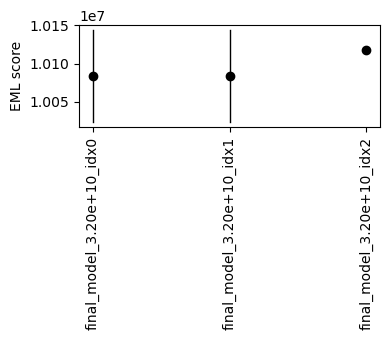

In [23]:
# define your ten model names

# compute EML scores and their standard errors
eml_scores, eml_std_errs = kpms.expected_marginal_likelihoods(PROJECT_DIR_FULL, model_names)

# pick the best model
best_model_name = model_names[np.argmax(eml_scores)]
print(f"Best model: {best_model_name}")

# visualize the EML scores across the ensemble
kpms.plot_eml_scores(eml_scores, eml_std_errs, model_names)


In [ ]:
import keypoint_moseq as kpms
model, data, metadata, current_iter = kpms.load_checkpoint(PROJECT_DIR, MODEL_NAME)
results = kpms.extract_results(model, metadata, PROJECT_DIR, MODEL_NAME, save_results=False)

In [25]:
for model_name in model_names:
    # load the specific checkpoint
    model, data, metadata, current_iter = kpms.load_checkpoint(PROJECT_DIR_FULL, model_name)
    
    # extract results for this model
    results = kpms.extract_results(model, metadata, PROJECT_DIR_FULL, model_name, save_results=True)


Saved results to
./salient_kpms_1_ld7_jn24/final_model_3.20e+10_idx0/results.h5
Saved results to
./salient_kpms_1_ld7_jn24/final_model_3.20e+10_idx1/results.h5
Saved results to
./salient_kpms_1_ld7_jn24/final_model_3.20e+10_idx2/results.h5


In [87]:
MODEL_NAME = model_names[2]

In [88]:
model, data, metadata, current_iter = kpms.load_checkpoint(PROJECT_DIR_FULL, MODEL_NAME)
results = kpms.extract_results(model, metadata, PROJECT_DIR_FULL, MODEL_NAME, save_results=False)

In [89]:
config = kpms.load_config(PROJECT_DIR_FULL)

In [90]:
import os
import h5py
import numpy as np
import jax.numpy as jnp
from jax_moseq.utils import unbatch
from jax_moseq.models.keypoint_slds import estimate_coordinates

# compute the estimated coordinates
Y_est = estimate_coordinates(
    jnp.array(model['states']['x']),
    jnp.array(model['states']['v']),
    jnp.array(model['states']['h']),
    jnp.array(model['params']['Cd'])
)

# generate a dictionary with reconstructed coordinates for each recording
coordinates_est = unbatch(Y_est, *metadata)

In [91]:
coordinates_est.keys()

dict_keys(['T8_Tracking_video2021-06-08T12_40_22_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T17_Tracking_video2020-04-28T15_09_33_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T14_Tracking_video2020-04-28T08_33_27_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T1_Tracking_video2021-06-02T09_38_27_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T6_Tracking_video2021-06-03T13_10_29_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T4_Tracking_video2021-06-03T08_53_07_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T16_Tracking_video2020-04-28T12_58_13_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T7_Tracking_video2021-06-08T10_38_58_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T15_Tracking_video2020-04-28T10_41_05_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T9_Tracking_video2021-06-08T14_24_19_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T12_Tracking_video2021-0

In [92]:
coordinates_est['T8_Tracking_video2021-06-08T12_40_22_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000'].shape

(100801, 10, 2)

In [93]:
for k, v in model['states'].items():
    print(k, v.shape)

h (209, 10030)
s (209, 10030, 10)
v (209, 10030, 2)
x (209, 10030, 7)
z (209, 10027)


In [94]:
for k, v in model['params'].items():
    print(k, v.shape)

Ab (100, 7, 22)
Cd (18, 8)
Q (100, 7, 7)
betas (100,)
pi (100, 100)
sigmasq (10,)


In [95]:
for k, v in config.items():
    # try .shape first; getattr(v, 'shape', None) will be None if no .shape
    shape = getattr(v, 'shape', None)
    if shape is None:
        try:
            # if it has a __len__, len(v) will work
            shape = len(v)
        except TypeError:
            # neither .shape nor len → skip
            continue
    print(k, shape)


bodyparts 10
use_bodyparts 10
skeleton 11
anterior_bodyparts 1
posterior_bodyparts 1
error_estimator 2
obs_hypparams 4
ar_hypparams 4
trans_hypparams 4
cen_hypparams 1
recording_name_suffix 0
video_dir 61
keypoint_colormap 6
anterior_idxs (1,)
posterior_idxs (1,)


In [96]:
for k, v in coordinates_est.items():
    print(k, v.shape)

T8_Tracking_video2021-06-08T12_40_22_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000 (100801, 10, 2)
T17_Tracking_video2020-04-28T15_09_33_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000 (100801, 10, 2)
T14_Tracking_video2020-04-28T08_33_27_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000 (100801, 10, 2)
T1_Tracking_video2021-06-02T09_38_27_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000 (100801, 10, 2)
T6_Tracking_video2021-06-03T13_10_29_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000 (100801, 10, 2)
T4_Tracking_video2021-06-03T08_53_07_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000 (100801, 10, 2)
T16_Tracking_video2020-04-28T12_58_13_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000 (100801, 10, 2)
T7_Tracking_video2021-06-08T10_38_58_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000 (100801, 10, 2)
T15_Tracking_video2020-04-28T10_41_05_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000 (100801, 10, 2)
T9_Tracking_vid

### Trajectory plots

Saving trajectory plots to ./salient_kpms_1_ld7_jn24/final_model_3.20e+10_idx2/trajectory_plots


Generating trajectory plots: 100%|██████| 48/48 [00:12<00:00,  3.78it/s]


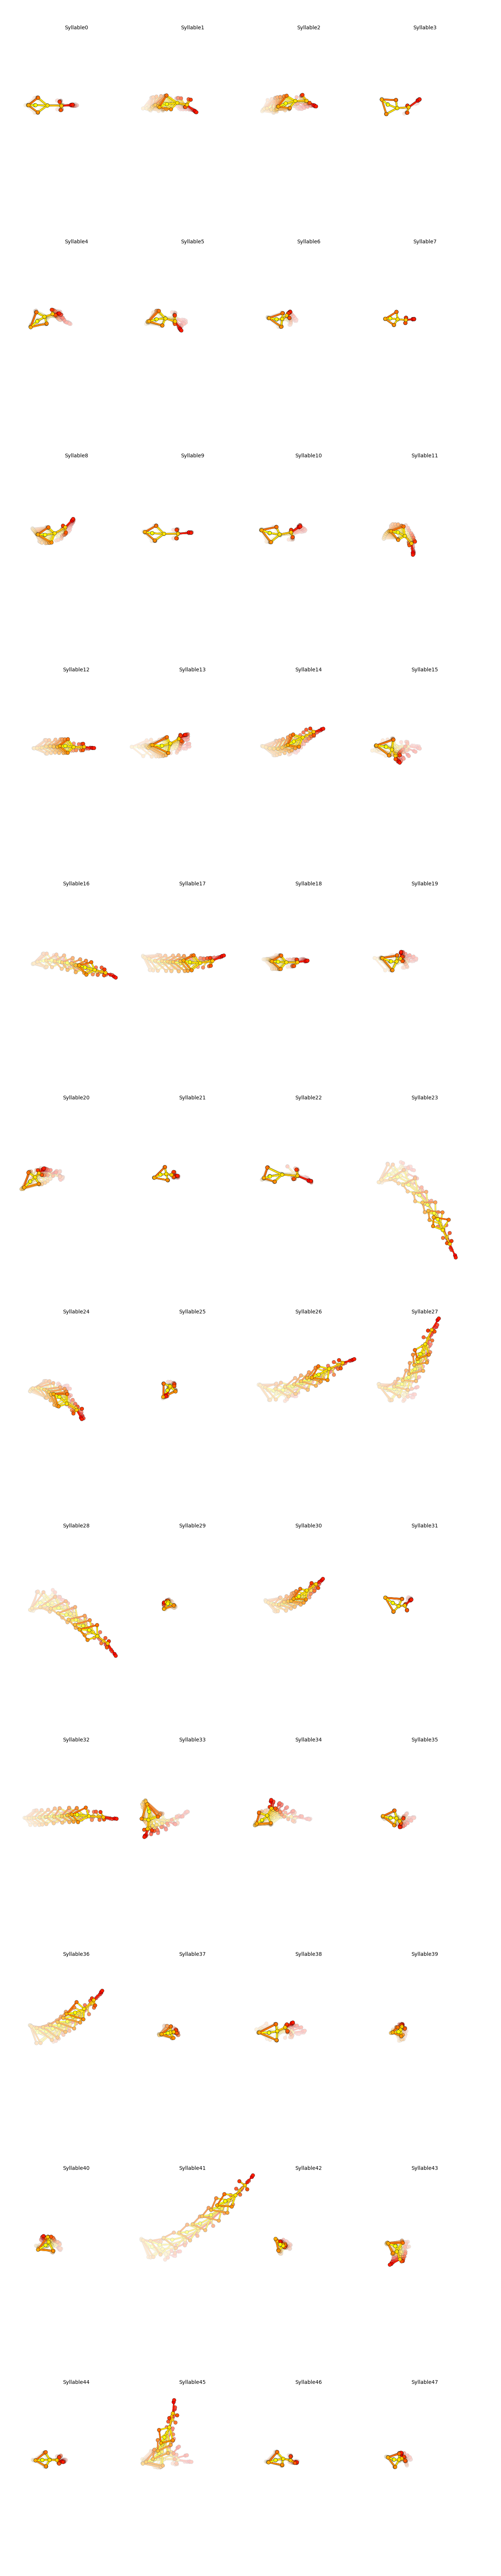

In [97]:
#perm = kpms.reindex_syllables_in_checkpoint(PROJECT_DIR, MODEL_NAME)

config['bodyparts'] = config['use_bodyparts']
kpms.generate_trajectory_plots(coordinates_est, results, PROJECT_DIR_FULL, MODEL_NAME, fps=60, min_frequency=0.003, min_duration=3, **config)

In [98]:
video_path

PosixPath('/home/fsp585/Desktop/FiberphotometryCode/src_oft/soeren/video_files')

In [99]:
for k in coordinates_est.keys():
    print(k)

T8_Tracking_video2021-06-08T12_40_22_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T17_Tracking_video2020-04-28T15_09_33_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T14_Tracking_video2020-04-28T08_33_27_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T1_Tracking_video2021-06-02T09_38_27_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T6_Tracking_video2021-06-03T13_10_29_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T4_Tracking_video2021-06-03T08_53_07_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T16_Tracking_video2020-04-28T12_58_13_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T7_Tracking_video2021-06-08T10_38_58_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T15_Tracking_video2020-04-28T10_41_05_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T9_Tracking_video2021-06-08T14_24_19_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T12_Tracking_video2021-06-10T13_04_33_Crop_DLC_resnet50_DLC_IFxDN_

### Grid movie preprocessing and generation

In [ ]:
import os
import pprint # Make sure pprint is imported for nice printing

def map_syllable_parts_to_videos(video_frame_indexes: dict, video_dir: str) -> dict:
    """
    Maps syllable part keys (e.g., '..._part1') to their corresponding video paths.

    This function is designed to work after keypoint-MoSeq splits a single
    recording into multiple parts during model fitting. It ensures that every key
    in the video_frame_indexes dictionary is mapped to the correct video file.

    Args:
        video_frame_indexes: The dictionary returned by the syllable generation step,
                             where keys may have '_partX' suffixes.
        video_dir: The path to the directory containing the video files.

    Returns:
        A dictionary where keys are the syllable part keys and values are the
        full paths to the single corresponding video file.
    """
    video_extensions = ('.mp4', '.avi', '.mov', '.mkv')
    video_files = [f for f in os.listdir(video_dir) if f.lower().endswith(video_extensions)]
    
    video_path_map = {}
    
    # Iterate through the keys of the video_frame_indexes dictionary
    for part_key in video_frame_indexes.keys():
        
        # Find the original H5 base name by stripping any '_partX' suffix.
        # We split the string at '_part' and take the first piece.
        h5_base_name = part_key.split('_part')[0]
        
        try:
            # Use the same logic as before to find the video's root name from the H5 base name
            video_root = h5_base_name.split('DLC_')[0]

            # Find the matching video file in the video directory
            found_match = False
            for video_file in video_files:
                if video_file.startswith(video_root):
                    # CRITICAL: Map the *original part_key* to the found video path.
                    # This ensures every part maps back to the same, single video file.
                    video_path_map[part_key] = os.path.join(video_dir, video_file)
                    found_match = True
                    break # Match found, move to the next part_key
            
            if not found_match:
                 print(f"Warning: No matching video found for key: {part_key}")

        except IndexError:
            print(f"Warning: Could not parse '{part_key}'. 'DLC_' delimiter not found. Skipping.")

    return video_path_map

In [ ]:
# --- Define the paths to your directories ---
VIDEO_DIRECTORY = '/home/fsp585/Desktop/FiberphotometryCode/src_oft/jonathan_full/video_files'

# --- Call the NEW function to get the correct mapping ---
# It uses the keys from video_frame_indexes as the source of truth.
h5_to_video_map_corrected = map_syllable_parts_to_videos(
    video_frame_indexes=video_frame_indexes,
    video_dir=VIDEO_DIRECTORY
)

# --- Print the results nicely to verify ---
print("--- Corrected File Mapping Results ---")
pprint.pprint(h5_to_video_map_corrected)

In [100]:
centroids, headings = kpms.get_centroids_headings(coordinates_est, **config)

In [101]:
for k in results.keys():
    print(k)

T8_Tracking_video2021-06-08T12_40_22_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T17_Tracking_video2020-04-28T15_09_33_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T14_Tracking_video2020-04-28T08_33_27_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T1_Tracking_video2021-06-02T09_38_27_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T6_Tracking_video2021-06-03T13_10_29_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T4_Tracking_video2021-06-03T08_53_07_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T16_Tracking_video2020-04-28T12_58_13_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T7_Tracking_video2021-06-08T10_38_58_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T15_Tracking_video2020-04-28T10_41_05_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T9_Tracking_video2021-06-08T14_24_19_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000
T12_Tracking_video2021-06-10T13_04_33_Crop_DLC_resnet50_DLC_IFxDN_

In [102]:
str(video_path)

'/home/fsp585/Desktop/FiberphotometryCode/src_oft/soeren/video_files'

In [103]:
config['video_dir'] = str(video_path)

In [104]:
results.keys()

dict_keys(['T8_Tracking_video2021-06-08T12_40_22_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T17_Tracking_video2020-04-28T15_09_33_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T14_Tracking_video2020-04-28T08_33_27_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T1_Tracking_video2021-06-02T09_38_27_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T6_Tracking_video2021-06-03T13_10_29_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T4_Tracking_video2021-06-03T08_53_07_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T16_Tracking_video2020-04-28T12_58_13_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T7_Tracking_video2021-06-08T10_38_58_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T15_Tracking_video2020-04-28T10_41_05_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T9_Tracking_video2021-06-08T14_24_19_Crop_DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000', 'T12_Tracking_video2021-0

In [105]:
manual_windows

{'T1_Tracking_video2021-06-02T09_38_27_Crop_': (14400, 115200),
 'T2_Tracking_video2021-06-02T11_38_59_Crop_': (9600, 110400),
 'T3_Tracking_video2021-06-02T13_40_32_Crop_': (8400, 109200),
 'T4_Tracking_video2021-06-03T08_53_07_Crop_': (12600, 113400),
 'T5_Tracking_video2021-06-03T10_51_44_Crop_': (10800, 111600),
 'T6_Tracking_video2021-06-03T13_10_29_Crop_': (12600, 113400),
 'T7_Tracking_video2021-06-08T10_38_58_Crop_': (10800, 111600),
 'T8_Tracking_video2021-06-08T12_40_22_Crop_': (15000, 115800),
 'T9_Tracking_video2021-06-08T14_24_19_Crop_': (16800, 117600),
 'T10_Tracking_video2021-06-10T09_27_05_Crop_': (12000, 112800),
 'T11_Tracking_video2021-06-10T11_24_58_Crop_': (10800, 111600),
 'T12_Tracking_video2021-06-10T13_04_33_Crop_': (8400, 109200),
 'T13_Tracking_video2020-04-24T15_10_25_Crop_': (11400, 112200),
 'T14_Tracking_video2020-04-28T08_33_27_Crop_': (12000, 112800),
 'T15_Tracking_video2020-04-28T10_41_05_Crop_': (12000, 112800),
 'T16_Tracking_video2020-04-28T12_58_

In [106]:
video_frame_indexes = {k + 'DLC_resnet50_DLC_IFxDN_SalientMar12shuffle1_760000' : np.arange(manual_windows[k][0], manual_windows[k][1] + 1)\
                       for k in manual_windows}

In [107]:
kpms.generate_grid_movies(results, PROJECT_DIR_FULL, MODEL_NAME, coordinates=coordinates_est, 
                          video_frame_indexes=video_frame_indexes, fps=60, **config);

Writing grid movies to ./salient_kpms_1_ld7_jn24/final_model_3.20e+10_idx2/grid_movies


/home/fsp585/miniforge3/envs/keypoint_moseq/lib/python3.9/site-packages/keypoint_moseq/viz.py:1325: UserWarning:


Videos will be downscaled by a factor of 0.65 so that the grid movies
are under 1920 pixels. Use `max_video_size` to increase or decrease
this size limit.





Using window size of 496 pixels


Generating grid movies: 100%|███████████| 38/38 [05:38<00:00,  8.92s/it]


In [ ]:
video_frame_indexes

In [ ]:
# --- 1. Align Dictionaries to a Common Set of Keys ---
# The AssertionError indicates a mismatch between the keys in `results` (from the model)
# and `video_frame_indexes` (from the syllable generation step).
# We will create temporary versions of all input dicts containing only the keys they share.

print("--- Aligning input dictionaries to a common set of keys... ---")

# Find the set of keys that exist in BOTH `results` and `video_frame_indexes_30fps`.
keys_results = set(results.keys())
keys_frames = set(video_frame_indexes.keys())
common_keys = keys_results.intersection(keys_frames)

print(f"Original `results` keys: {len(keys_results)}")
print(f"Original `video_frame_indexes` keys: {len(keys_frames)}")
print(f"Found {len(common_keys)} common keys to use for movie generation.")

# For debugging, show the differences (optional, can be commented out)
if len(keys_results) != len(common_keys) or len(keys_frames) != len(common_keys):
    print("\nKeys in results ONLY:", keys_results - keys_frames)
    print("Keys in frames ONLY:", keys_frames - keys_results)
    print("-" * 20)

# Create new, temporary dictionaries filtered to only contain the common keys.
results_common = {k: results[k] for k in common_keys}
video_frame_indexes_common = {k: video_frame_indexes[k] for k in common_keys}
h5_to_video_map_common = {k: h5_to_video_map_corrected[k] for k in common_keys if k in h5_to_video_map_corrected}
coordinates_common = {k: coordinates_est[k] for k in common_keys if k in coordinates_est}
centroids_common = {k: centroids[k] for k in common_keys if k in centroids}
headings_common = {k: headings[k] for k in common_keys if k in headings}


# --- 2. Create a temporary copy of the config to avoid the 'fps' conflict ---
config_for_movies = config.copy()
if 'fps' in config_for_movies:
    del config_for_movies['fps']


# --- 3. Now, call the function with the ALIGNED and CORRECTED data ---
print("\n--- Generating grid movies with aligned data... ---")
kpms.generate_grid_movies(
    results_common,
    PROJECT_DIR,
    MODEL_NAME,
    video_paths=h5_to_video_map_common,
    coordinates=coordinates_common,
    centroids=centroids_common,
    headings=headings_common,
    fps=60,
    video_frame_indexes=video_frame_indexes_common,
    overlay_keypoints=False,
    **config_for_movies
)

### Group assignment and syllable labeling

In [ ]:
import re

# metadata_names is the list/array of all result names (e.g., metadata[0])
metadata_names = metadata[0]

for sess in sessions:
    sess.result_names = []
    h5_path = sess.kpms_h5_path
    for name in metadata_names:
        # strip "_part#" only for matching
        base = re.sub(r'_part\d+$', '', name)
        if base in h5_path and name not in sess.result_names:
            # append the full original name (with part suffix)
            sess.result_names.append(name)

In [ ]:
import pandas as pd

# build a list of dicts
rows = []
for sess in sessions:
    for name in sess.result_names:
        rows.append({
            "name": name,
            "group": sess.genotype
        })

# make a DataFrame
index_df = pd.DataFrame(rows)

# (optionally) save it back out so your interactive widget picks it up
index_df.to_csv(os.path.join(PROJECT_DIR, "index.csv"), index=False)

# inspect
print(index_df.head())


In [ ]:
moseq_df = kpms.compute_moseq_df(PROJECT_DIR, MODEL_NAME, smooth_heading=True)

In [ ]:
moseq_df

In [ ]:
stats_df = kpms.compute_stats_df(
    PROJECT_DIR,
    MODEL_NAME,
    moseq_df,
    min_frequency=0.005,  # threshold frequency for including a syllable in the dataframe
    groupby=["group", "name"],  # column(s) to group the dataframe by
    fps=60,
)  # frame rate of the video from which keypoints were inferred

stats_df

In [ ]:
#kpms.label_syllables(PROJECT_DIR, MODEL_NAME, moseq_df)

In [ ]:
sessions[0].kpms_h5_path

In [ ]:
#kpms.interactive_group_setting

### Plotting setup and more checks

In [ ]:
from fiberphotometry.config import PLOTTING_CONFIG
from fiberphotometry.processing.plotting_setup import PlottingSetup

In [ ]:
PlottingSetup(**PLOTTING_CONFIG['cpt']).apply_plotting_setup_to_sessions(sessions)

In [ ]:
plt.plot(sessions[0].all_results['syllable'])

In [ ]:
sessions[0].dfs.data.keys()

In [ ]:
sessions[0].dfs.data['synchronized_data_tracking_0']

In [ ]:
sessions[0].dfs.data['phot_470']

### Syllable based signatures

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import sem
from scipy.signal import savgol_filter

# --- Analysis & Smoothing Parameters ---
SAMPLING_RATE = 80
WINDOW_SECONDS = 10
SMOOTHING_WINDOW = 25
SMOOTHING_POLY_ORDER = 3
CONFIDENCE_LEVEL = 1.96
WINDOW_SAMPLES = int(WINDOW_SECONDS * SAMPLING_RATE)
TOTAL_SAMPLES = 2 * WINDOW_SAMPLES
SIGNAL_COLS = ['signal_0_470_dff_z', 'signal_1_470_dff_z']

# --- Syllable Label Setup (no reindexing) ---
LABEL_CSV_PATH = '/home/fsp585/Desktop/FiberphotometryCode/tests/kpms_all_sessions_frac_1_ld9_jn24/final_model_1.20e+06_idx1/syll_info.csv'
labels_df = pd.read_csv(LABEL_CSV_PATH)
labels_df['label'] = labels_df['label'].fillna('').str.strip()

# Map original syllable ID to label; fallback to "non-common" if missing/empty
syllable_id_to_label = {
    int(row.syllable): row.label if row.label else "non-common"
    for _, row in labels_df.iterrows()
}

# --- Data Processing Function ---
def process_session_data(session):
    """Processes a single session to extract, smooth, and baseline-correct traces."""
    df = session.dfs.data['synchronized_data_tracking_0']
    
    onsets = df[(df['syllable'].notna()) & (df['syllable'] != df['syllable'].shift(1))]
    
    syllable_traces = {s: {col: [] for col in SIGNAL_COLS} for s in onsets['syllable'].unique()}
    for index, row in onsets.iterrows():
        syllable = row['syllable']
        start_idx = index - WINDOW_SAMPLES
        end_idx = index + WINDOW_SAMPLES
        if start_idx >= 0 and end_idx <= len(df):
            for col in SIGNAL_COLS:
                trace = df.loc[start_idx:end_idx-1, col].values
                if len(trace) == TOTAL_SAMPLES:
                    syllable_traces[syllable][col].append(trace)

    processed_traces = {s: {col: [] for col in SIGNAL_COLS} for s in syllable_traces.keys()}
    for syllable, signals in syllable_traces.items():
        for signal_col, traces in signals.items():
            for trace in traces:
                trace_series = pd.Series(trace)
                interpolated = trace_series.interpolate(method='linear', limit_direction='both')
                smoothed = savgol_filter(interpolated, SMOOTHING_WINDOW, SMOOTHING_POLY_ORDER)
                baseline_value = smoothed[WINDOW_SAMPLES]
                normalized_trace = smoothed - baseline_value
                processed_traces[syllable][signal_col].append(normalized_trace)
                
    return processed_traces

# --- Analysis & Plotting ---

# 1. Process every session
processed_list = [process_session_data(s) for s in sessions]

# 2. Gather all syllables present across sessions
all_syllables = sorted({
    syll for proc in processed_list for syll in proc.keys()
})
print("Syllables to plot:", all_syllables)

# 3. Determine unique brain regions and hemispheres from sessions' metadata
regions = sorted({region for s in sessions for region, _, _ in s.brain_regions})
hemispheres = sorted({
    s.signal_meta["_".join(col.split("_")[:2])][1]
    for s in sessions
    for col in SIGNAL_COLS
    if "_".join(col.split("_")[:2]) in s.signal_meta
})
time_vector = np.linspace(-WINDOW_SECONDS, WINDOW_SECONDS, TOTAL_SAMPLES)

# 4. Plot each syllable with hemisphere rows (top=left, bottom=right) and region columns
for syl_idx, syllable in enumerate(all_syllables):
    final_label = syllable_id_to_label.get(int(syllable), f"Unknown ID: {syllable}")
    
    hemis_order = ['left', 'right']  # top row = left, bottom = right
    n_rows = 2
    n_cols = len(regions)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols + 2, 8))  # width scales with regions
    fig.suptitle(f"Syllable Onset: '{final_label}' (Original ID: {int(syllable)})", fontsize=18)

    time_vector = np.linspace(-WINDOW_SECONDS, WINDOW_SECONDS, TOTAL_SAMPLES)

    for row_idx, hemisphere in enumerate(hemis_order):
        for col_idx, region in enumerate(regions):
            ax = axes[row_idx, col_idx] if n_rows > 1 else axes[col_idx]
            traces_by_genotype = {'KI': [], 'WT': []}

            for s, proc_data in zip(sessions, processed_list):
                meta = s.signal_meta
                for col in SIGNAL_COLS:
                    prefix = "_".join(col.split("_")[:2])
                    if prefix not in meta:
                        continue
                    region_meta = meta[prefix][0]
                    hemi_meta = meta[prefix][1]
                    if region_meta == region and hemi_meta == hemisphere:
                        traces = proc_data.get(syllable, {}).get(col, [])
                        traces_by_genotype[s.genotype].extend(traces)

            for geno, traces in traces_by_genotype.items():
                if not traces:
                    continue
                valid_traces = [t for t in traces if not np.isnan(t).any()]
                n_skipped = len(traces) - len(valid_traces)
                if n_skipped > 0:
                    print(f"Skipped {n_skipped} {geno} traces for syllable {syllable}, region {region}, hemisphere {hemisphere} due to NaNs")
                if not valid_traces:
                    continue

                arr = np.stack(valid_traces)
                m = arr.mean(axis=0)
                e = sem(arr, axis=0)
                lower = m - CONFIDENCE_LEVEL * e
                upper = m + CONFIDENCE_LEVEL * e

                color = 'darkblue' if geno == 'KI' else 'green'
                ax.plot(time_vector, m, label=f"{geno} (n={len(traces)})", color=color)
                ax.fill_between(time_vector, lower, upper, color=color, alpha=0.2)

            ax.set_title(f"{region} | {hemisphere}", fontsize=13)
            ax.axvline(0, color='crimson', linestyle='--', lw=2)
            ax.axhline(0, color='grey', linestyle=':', lw=1)
            if row_idx == n_rows - 1:
                ax.set_xlabel("Time from Onset (s)")
            if col_idx == 0:
                ax.set_ylabel("Normalized Signal (z-score)")
            ax.grid(True, linestyle=':')
            ax.legend(fontsize='small')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    if syl_idx < 30:
        plt.savefig(f'syl_{syl_idx}.png')
    plt.show()


In [ ]:
kpms.plot_syll_stats_with_sem(
    stats_df,
    PROJECT_DIR,
    MODEL_NAME,
    plot_sig=True,  # whether to mark statistical significance with a star
    thresh=0.05,  # significance threshold
    stat="frequency",  # statistic to be plotted (e.g. 'duration' or 'velocity_px_s_mean')
    order="stat",  # order syllables by overall frequency ("stat") or degree of difference ("diff")
    ctrl_group="a",  # name of the control group for statistical testing
    exp_group="b",  # name of the experimental group for statistical testing
    figsize=(8, 4),  # figure size
    groups=stats_df["group"].unique(),  # groups to be plotted
);


In [ ]:
normalize = "bigram"  # normalization method ("bigram", "rows" or "columns")

trans_mats, usages, groups, syll_include = kpms.generate_transition_matrices(
    PROJECT_DIR,
    MODEL_NAME,
    normalize=normalize,
    min_frequency=0.010,  # minimum syllable frequency to include
)

kpms.visualize_transition_bigram(
    PROJECT_DIR,
    MODEL_NAME,
    groups,
    trans_mats,
    syll_include,
    normalize=normalize,
    show_syllable_names=True,  # label syllables by index (False) or index and name (True)
)


In [ ]:

kpms.plot_transition_graph_group(
    PROJECT_DIR,
    MODEL_NAME,
    groups,
    trans_mats,
    usages,
    syll_include,
    layout="circular",  # transition graph layout ("circular" or "spring")
    show_syllable_names=False,  # label syllables by index (False) or index and name (True)
)


In [ ]:
kpms.plot_transition_graph_group(
    PROJECT_DIR,
    MODEL_NAME,
    groups,
    trans_mats,
    usages,
    syll_include,
    layout="circular",  # transition graph layout ("circular" or "spring")
    show_syllable_names=True,  # label syllables by index (False) or index and name (True)
)


In [ ]:
kpms.plot_transition_graph_difference(
    PROJECT_DIR, MODEL_NAME, groups, trans_mats, usages, syll_include, layout="circular", show_syllable_names=True
)  # transition graph layout ("circular" or "spring")